In [1]:
from gctm_jcgs_simulation_study_helpers import *
import os
import pickle

/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Warning: Due to run error dont forget to delete after rsync:
The first one of the following runs (should alsways be two)
- rvine_10D_500obs: Seed_15_No
- cvine_10D_125obs: Seed_61_Adaptive

- dvine_10_500obs actually runs with 125obs

In [2]:
# go up one in working directory to be in the same directory as the mlflow runs
os.chdir("..")

## Mlflow Wrangling and Plotting Functions

In [3]:
# create a plot where we input rvine_kld_dict_weighted_no_pen, rvine_kld_dict_lambda_pen and rvine_kld_dict_weighted_lambda_pen
# we then plot on the x axis the sample size e.g.g 125, 250, 500, 1000, 2000, 4000
# on the y axis we put the rel_kld_test
# for each we want the mean over seeds as a point and the upper 80 and lower 20 percentage quantile as wiskers

import numpy as np
import matplotlib.pyplot as plt

# Function to compute mean, 20th, and 80th percentiles
def compute_stats(data_dict, experiment_strings, metric = "rel_kld_test", lower_quantile=5, upper_quantile=95):
    means = []
    lower_quantiles = []
    upper_quantiles = []
    for size in experiment_strings:
        if metric is not False:
            values = data_dict[size][metric]
        else:
            values = data_dict[size]
        # drop extereme values above 5
        #values = [x for x in values if x < 3]
        means.append(np.nanmean(values))
        lower_quantiles.append(np.nanpercentile(values, lower_quantile))
        upper_quantiles.append(np.nanpercentile(values, upper_quantile))
        
        if np.isnan(values).sum() > 0:
            print("there are nan values in {}, the number is ".format(metric),np.isnan(values).sum())
        
    return means, lower_quantiles, upper_quantiles

def create_comparison_plot_one_scenario(
    kld_dict_no_lambda_pen,
    kld_dict_lambda_pen,
    kld_dict_weighted_lambda_pen,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125, 250, 500, 1000, 2000, 4000],
    experiment_strings = ["rvine_10_dim_125obs", "rvine_10_dim_250obs", "rvine_10_dim_1000obs", "rvine_10_dim_2000obs", "rvine_10_dim"],
    y_min = False,
    y_max = False,
    benchmark=False,
    legend=False,
    metric_str="AUC",
    upper_quantile=80,
    lower_quantile=20
):
    # Define sample sizes
    #experiment_strings = list(kld_dict_no_lambda_pen.keys())

    # Compute statistics for each method
    means_weighted_no_pen, lower_weighted_no_pen, upper_weighted_no_pen = compute_stats(kld_dict_no_lambda_pen, experiment_strings, metric, lower_quantile, upper_quantile)
    means_lambda_pen, lower_lambda_pen, upper_lambda_pen = compute_stats(kld_dict_lambda_pen, experiment_strings, metric, lower_quantile, upper_quantile)
    means_weighted_lambda_pen, lower_weighted_lambda_pen, upper_weighted_lambda_pen = compute_stats(kld_dict_weighted_lambda_pen, experiment_strings, metric, lower_quantile, upper_quantile)
    if benchmark is not False:
        means_benchmark, lower_benchmark, upper_benchmark = compute_stats(benchmark, experiment_strings, metric=False, lower_quantile=lower_quantile, upper_quantile=upper_quantile)

    # Define evenly spaced x positions for the sample sizes
    x_positions = np.arange(len(sample_sizes))

    # Updated plotting with side-by-side whisker plots
    offset = 0.2  # Offset for separating whisker plots within each sample size group

    plt.figure(figsize=(5, 4))

    # Adjusted x positions for each method
    if benchmark is not False:
        x_benchmark = x_positions - offset
        x_weighted_no_pen = x_positions - 0.33 * offset
        x_lambda_pen = x_positions + 0.33 * offset
        x_weighted_lambda_pen = x_positions + offset
        
        plt.errorbar(x_benchmark, means_benchmark, 
                yerr=[np.array(means_benchmark) - np.array(lower_benchmark),
                    np.array(upper_benchmark) - np.array(means_benchmark)],
                label="GGM", 
                fmt='o', linestyle='', capsize=5, color="#d62728") #red
    else:
        x_weighted_no_pen = x_positions - offset
        x_lambda_pen = x_positions
        x_weighted_lambda_pen = x_positions + offset

    # Plot each method with error bars
    plt.errorbar(x_weighted_no_pen, means_weighted_no_pen, 
                yerr=[np.array(means_weighted_no_pen) - np.array(lower_weighted_no_pen),
                    np.array(upper_weighted_no_pen) - np.array(means_weighted_no_pen)],
                label="No LASSO Penalty", 
                fmt='o', linestyle='', capsize=5, color="#1f77b4") #blue

    plt.errorbar(x_lambda_pen, means_lambda_pen, 
                yerr=[np.array(means_lambda_pen) - np.array(lower_lambda_pen),
                    np.array(upper_lambda_pen) - np.array(means_lambda_pen)],
                label="LASSO Penalty", 
                fmt='o', linestyle='', capsize=5, color="#ff7f0e") #orange

    plt.errorbar(x_weighted_lambda_pen, means_weighted_lambda_pen, 
                yerr=[np.array(means_weighted_lambda_pen) - np.array(lower_weighted_lambda_pen),
                    np.array(upper_weighted_lambda_pen) - np.array(means_weighted_lambda_pen)],
                label="Adaptive LASSO Penalty", 
                fmt='o', linestyle='', capsize=5, color="#2ca02c") #green

    # Formatting
    plt.xticks(x_positions, sample_sizes)  # Replace numeric x positions with sample size labels
    plt.xlabel("Sample Size")
    plt.ylabel(metric_str)
    #plt.title(title_str + ": " + metric)
    if legend == True:
        plt.legend()
    plt.grid(True, which="both", linestyle="--", linewidth=0.5)
    # min 0.5 max 1 on the y axis
    if y_min is not False and y_max is not False:
        plt.ylim(y_min, y_max)
    #plt.show()

In [4]:
def get_rel_kld_experiment(experiment_name="rvine_10D_125obs", 
                                      name_ending_look_for=False, 
                                      name_endings_not_look_for_list=False,
                                      seed_min=False, 
                                      seed_max=False,
                                      kld_available=False,
                                      print_info=False,
                                      print_run_names=False,
                                      copula=False):
    
    experiment = mlflow.get_experiment_by_name(experiment_name) 
    df_runs = mlflow.search_runs([experiment.experiment_id])
    subset = df_runs
    
    if name_ending_look_for is not False:
        subset = subset[[name_ending_look_for in subset.iloc[i]["tags.mlflow.runName"] for i in range(subset.shape[0])]]
        
    if name_endings_not_look_for_list is not False:
        for name_ending_not_look_for in name_endings_not_look_for_list:
            subset = subset[[name_ending_not_look_for not in subset.iloc[i]["tags.mlflow.runName"] for i in range(subset.shape[0])]]
    
    if seed_min is not False:
        subset = subset[[int(subset.iloc[i]["tags.seed_value"]) >= seed_min for i in range(subset.shape[0])]]
    if seed_max is not False:
        subset = subset[[int(subset.iloc[i]["tags.seed_value"]) <= seed_max for i in range(subset.shape[0])]]
    

    subset_pen = subset#[0:15] # if the most recent seed is still running
    if print_run_names is True: 
        print(subset_pen["tags.mlflow.runName"].to_numpy())
        print(subset_pen["tags.mlflow.runName"].to_numpy().shape)
    
    
    dict_rel_kld = {}

    list_rel_kld_test = []
    list_rel_kld_train = []
    for i in range(len(subset)):
        subset_pen = subset.iloc[i]
        test_rel_kld_pen = subset_pen["metrics.relative_kld_gtm_test"]
        train_rel_kld_pen = subset_pen["metrics.relative_kld_gtm_train"]
        
        list_rel_kld_test.append(test_rel_kld_pen) 
        list_rel_kld_train.append(train_rel_kld_pen)
        
    dict_rel_kld["rel_kld_test"] = list_rel_kld_test
    dict_rel_kld["rel_kld_train"] = list_rel_kld_train
    
    return dict_rel_kld


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def gather_data_for_violin(data_dict, experiment_strings, method_name, metric="rel_kld_test"):
    rows = []
    for i, size in enumerate(experiment_strings):
        if metric is not False:
            values = data_dict[size][metric]
        else:
            values = data_dict[size]
        for v in values:
            rows.append({"SampleSize": size, "SampleSizeInt": int(''.join([c for c in size if c.isdigit()])), "Method": method_name, "Value": v})
    return rows

def create_comparison_violin_plot(
    kld_dict_no_lambda_pen,
    kld_dict_lambda_pen,
    kld_dict_weighted_lambda_pen,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125, 250, 500, 1000, 2000, 4000],
    experiment_strings = ["rvine_10_dim_125obs", "rvine_10_dim_250obs", "rvine_10_dim_500obs", "rvine_10_dim_1000obs", "rvine_10_dim_2000obs", "rvine_10_dim_4000obs"],
    y_min = False,
    y_max = False,
    benchmark=False,
    legend=False,
    metric_str="AUC"
):
    # Gather all data into a dataframe for seaborn plotting
    data = []
    data.extend(gather_data_for_violin(kld_dict_no_lambda_pen, experiment_strings, "No LASSO Penalty", metric))
    data.extend(gather_data_for_violin(kld_dict_lambda_pen, experiment_strings, "LASSO Penalty", metric))
    data.extend(gather_data_for_violin(kld_dict_weighted_lambda_pen, experiment_strings, "Adaptive LASSO Penalty", metric))
    if benchmark is not False:
        data.extend(gather_data_for_violin(benchmark, experiment_strings, "GGM", metric=False))
    df = pd.DataFrame(data)
    df['SampleSizeInt'] = df['SampleSizeInt'].astype(int)
    
    plt.figure(figsize=(12,4))
    sns.violinplot(
        data=df, 
        x='SampleSizeInt', 
        y='Value', 
        hue='Method', 
        split=False,     # DO NOT split—puts violins side by side!
        inner=None,
        width=0.2,       # Thinner violins
        dodge=True,      # Separate methods at each sample size
        palette={"No LASSO Penalty":"#1f77b4", "LASSO Penalty":"#ff7f0e", "Adaptive LASSO Penalty":"#2ca02c", "GGM":"#d62728"}
    )
    # Overlay medians if you wish
    sns.pointplot(
        data=df, 
        x="SampleSizeInt", 
        y="Value", 
        hue="Method", 
        dodge=0.2, 
        join=False, 
        palette={"No LASSO Penalty":"#1f77b4", "LASSO Penalty":"#ff7f0e", "Adaptive LASSO Penalty":"#2ca02c", "GGM":"#d62728"},
        markers="d",
        legend=False,
        ci=None,
    )

    plt.xlabel("Sample Size")
    plt.ylabel(metric_str)
    plt.title(title_str)
    if legend:
        plt.legend()
    else:
        plt.legend([],[], frameon=False)
    plt.grid(True, linestyle="--", linewidth=0.5, axis='y')
    if y_min is not False and y_max is not False:
        plt.ylim(y_min, y_max)
    plt.tight_layout()
    plt.show()

In [6]:
def get_kld_dicts(experiment_name_list, seed_min=0, seed_max=99, kld_available=False, print_info=False, print_run_names=False, copula=False):
    rvine_kld_dict_no = {}
    rvine_kld_dict_lasso = {}
    rvine_kld_dict_adaptive = {}
    # Config for each type
    configs = [
        ("No",      ["Adaptive", "Lasso"],     rvine_kld_dict_no),
        ("Lasso",   ["Adaptive", "No"],        rvine_kld_dict_lasso),
        ("Adaptive",["Lasso", "No"],           rvine_kld_dict_adaptive)
    ]
    for name_ending_look_for, name_endings_not_look_for_list, result_dict in configs:
        for experiment_name in experiment_name_list:
            result_dict[experiment_name] = get_rel_kld_experiment(
                experiment_name=experiment_name,
                name_ending_look_for=name_ending_look_for,
                name_endings_not_look_for_list=name_endings_not_look_for_list,
                seed_min=seed_min,
                seed_max=seed_max,
                kld_available=kld_available,
                print_info=print_info,
                print_run_names=print_run_names,
                copula=copula
            )
    return rvine_kld_dict_no, rvine_kld_dict_lasso, rvine_kld_dict_adaptive

### auc functions

In [7]:
def get_auc_across_metrics_experiment(experiment_name, 
                                            name_ending_look_for=False, 
                                            name_endings_not_look_for_list=False,
                                            seed_min=1, 
                                            seed_max=30,
                                            print_run_names=False,):
    
    experiment = mlflow.get_experiment_by_name(experiment_name) 
    df_runs = mlflow.search_runs([experiment.experiment_id])
    subset = df_runs
    
    if name_ending_look_for is not False:
        subset = subset[[name_ending_look_for in subset.iloc[i]["tags.mlflow.runName"] for i in range(subset.shape[0])]]
        
    if name_endings_not_look_for_list is not False:
        for name_ending_not_look_for in name_endings_not_look_for_list:
            subset = subset[[name_ending_not_look_for not in subset.iloc[i]["tags.mlflow.runName"] for i in range(subset.shape[0])]]
    
    if seed_min is not False:
        subset = subset[[int(subset.iloc[i]["tags.seed_value"]) >= seed_min for i in range(subset.shape[0])]]
    if seed_max is not False:
        subset = subset[[int(subset.iloc[i]["tags.seed_value"]) <= seed_max for i in range(subset.shape[0])]]
    

    subset_pen = subset#[0:15] # if the most recent seed is still running
    if print_run_names is True: 
        print(subset_pen["tags.mlflow.runName"].to_numpy())
        print(subset_pen["tags.mlflow.runName"].to_numpy().shape)
    
    
    # First, get the list of all columns containing "auc"
    auc_columns = [col for col in subset.columns if 'auc' in col]

    dict_auc = {}

    # Initialize each auc column's list in the dictionary
    for auc_col in auc_columns:
        dict_auc[auc_col] = []

    # Loop over the rows and collect values for each auc column
    for i in range(len(subset)):
        row = subset.iloc[i]
        for auc_col in auc_columns:
            dict_auc[auc_col].append(float(row[auc_col]))
    
    return dict_auc


In [8]:
def get_auc_dicts_all(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    print_run_names=False
):
    auc_dict_no = {}
    auc_dict_lasso = {}
    auc_dict_adaptive = {}

    configs = [
        ("No",      ["Adaptive", "Lasso"],     auc_dict_no),
        ("Lasso",   ["Adaptive", "No"],        auc_dict_lasso),
        ("Adaptive",["Lasso", "No"],           auc_dict_adaptive)
    ]
    for name_look_for, name_not_look_for, result_dict in configs:
        for experiment_name in experiment_name_list:
            result_dict[experiment_name] = get_auc_across_metrics_experiment(
                experiment_name=experiment_name,
                name_ending_look_for=name_look_for,
                name_endings_not_look_for_list=name_not_look_for,
                seed_min=seed_min,
                seed_max=seed_max,
                print_run_names=print_run_names
            )
            
    return auc_dict_no, auc_dict_lasso, auc_dict_adaptive


## Finding Error

In [9]:
experiment_name_list = ["rvine_10D_125obs"]
kld_no, kld_lasso, kld_adaptive = get_kld_dicts(experiment_name_list)

In [10]:
experiment_name_list = ["dvine_10D_125obs"]
kld_no_d, kld_lasso_d, kld_adaptive_d = get_kld_dicts(experiment_name_list)

In [22]:
experiment_name_list = ["cvine_10D_125obs"]
kld_no_c, kld_lasso_c, kld_adaptive_c = get_kld_dicts(experiment_name_list)

In [25]:
np.array(kld_no['rvine_10D_125obs'])

array({'rel_kld_test': [0.8865, 0.7252, 0.9567, 0.7463, 0.8892, 0.7902, 1.1075, 0.7551, 0.5944, 0.8885, 0.9094, 1.1524, 0.8491, 0.8724, 0.7862, 1.2241, 0.9366, 0.8075, 0.8332, 0.819, 0.9913, 0.783, 0.7106, 0.8499, 1.2473, 0.7774, 1.1369, 0.8961, 0.865, 0.8459, 0.6718, 0.854, 1.7162, 0.9484, 0.8281, 0.8637, 0.759, 0.744, 1.055, 0.9714, 0.8871, 0.9369, 0.9555, 0.7661, 0.9351, 0.7989, 0.7844, 1.0613, 0.7969, 0.7573, 0.7403, 0.8307, 0.7594, 0.9139, 0.8099, 0.8359, 0.9338, 0.9418, 1.2007, 0.8254, 0.6506, 0.5531, 0.7478, 0.9331, 0.8551, 1.2078, 1.0402, 0.811, 0.7044, 0.9338, 0.8757, 0.8375, 0.9446, 0.8616, 0.6554, 0.9278, 1.1082, 1.0107, 0.9071, 0.9648, 0.8338, 0.7543, 0.8423, 0.8247, 1.0651, 1.2478, 1.3197, 0.9491, 0.7431, 0.8853, 0.7908, 0.8183, 0.8696, 0.8241, 0.8418, 0.7427, 0.8113, 1.1048, 0.7843, 1.0884], 'rel_kld_train': [0.3862, 0.5582, 0.3595, 0.3691, 0.5734, 0.1659, -0.0154, 0.4019, 0.2619, -0.0348, 0.0428, -0.091, 0.5061, 0.556, 0.426, 0.0464, 0.2891, 0.2282, 0.5332, 0.5949, 0.116

In [26]:
pd.DataFrame({"r":np.array(kld_no['rvine_10D_125obs']['rel_kld_test']),
              "d":np.array(kld_no_d['dvine_10D_125obs']['rel_kld_test']),
              "c":np.array(kld_no_c['cvine_10D_125obs']['rel_kld_test']) 
              })

,r,d,c
0,0.8865,1.0221,0.8851
1,0.7252,0.7064,0.7092
2,0.9567,0.8926,0.9277
3,0.7463,0.6792,0.6764
4,0.8892,0.7520,0.9369
...,...,...,...
95,0.7427,0.7241,0.7274
96,0.8113,0.8705,0.9163
97,1.1048,1.1041,1.1842
98,0.7843,0.6849,0.7611


## Relative KLD Results

### R-vine

In [15]:
# Usage:
experiment_name_list = ["rvine_10D_125obs"]
experiment_name_list = ["rvine_10D_125obs", "rvine_10D_500obs", "rvine_10D_2000obs"]
kld_no, kld_lasso, kld_adaptive = get_kld_dicts(experiment_name_list)

there are nan values in rel_kld_test, the number is  1
there are nan values in rel_kld_test, the number is  1


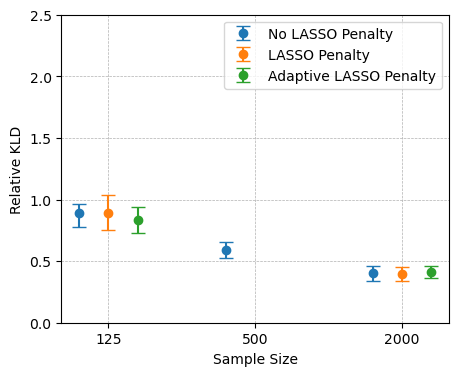

In [20]:
create_comparison_plot_one_scenario(
    kld_no,
    kld_lasso,
    kld_adaptive,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125, 500, 2000],
    experiment_strings=experiment_name_list,
    y_min = 0.,
    y_max = 2.5,
    legend=True,
    metric_str="Relative KLD"
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

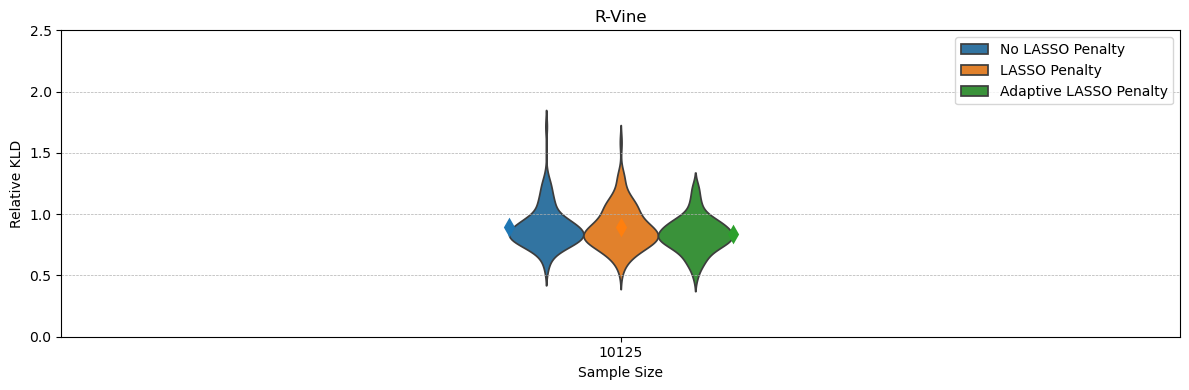

In [12]:
create_comparison_violin_plot(
    kld_no,
    kld_lasso,
    kld_adaptive,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.,
    y_max = 2.5,
    legend=True,
    metric_str="Relative KLD"
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

### D-vine

In [13]:
# Usage:
experiment_name_list = ["dvine_10D_125obs", "dvine_10D_500obs", "dvine_10D_2000obs"]
kld_no, kld_lasso, kld_adaptive = get_kld_dicts(experiment_name_list, seed_min=0, seed_max=24)

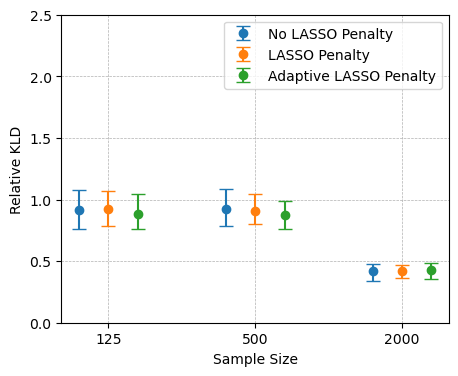

In [14]:
create_comparison_plot_one_scenario(
    kld_no,
    kld_lasso,
    kld_adaptive,
    metric = "rel_kld_test",
    title_str = "D-Vine",
    sample_sizes = [125, 500, 2000],
    experiment_strings=experiment_name_list,
    y_min = 0.,
    y_max = 2.5,
    legend=True,
    metric_str="Relative KLD"
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

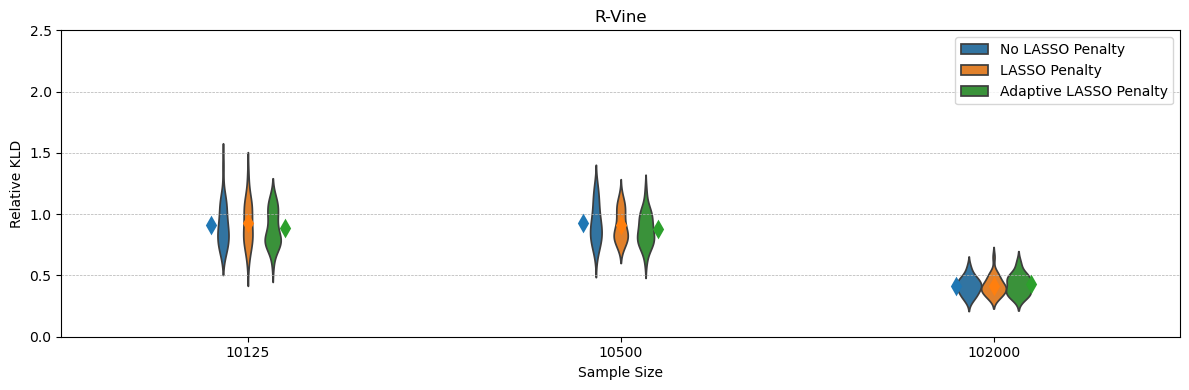

In [15]:
create_comparison_violin_plot(
    kld_no,
    kld_lasso,
    kld_adaptive,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.,
    y_max = 2.5,
    legend=True,
    metric_str="Relative KLD"
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

### C-vine

In [16]:
# Usage:
experiment_name_list = ["cvine_10D_125obs", "cvine_10D_500obs"]
kld_no, kld_lasso, kld_adaptive = get_kld_dicts(experiment_name_list)

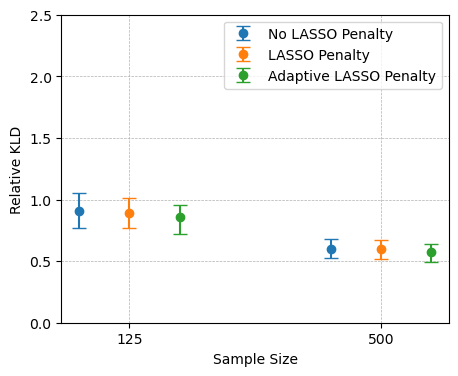

In [17]:
create_comparison_plot_one_scenario(
    kld_no,
    kld_lasso,
    kld_adaptive,
    metric = "rel_kld_test",
    sample_sizes = [125, 500],
    experiment_strings=experiment_name_list,
    y_min = 0.,
    y_max = 2.5,
    legend=True,
    metric_str="Relative KLD"
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

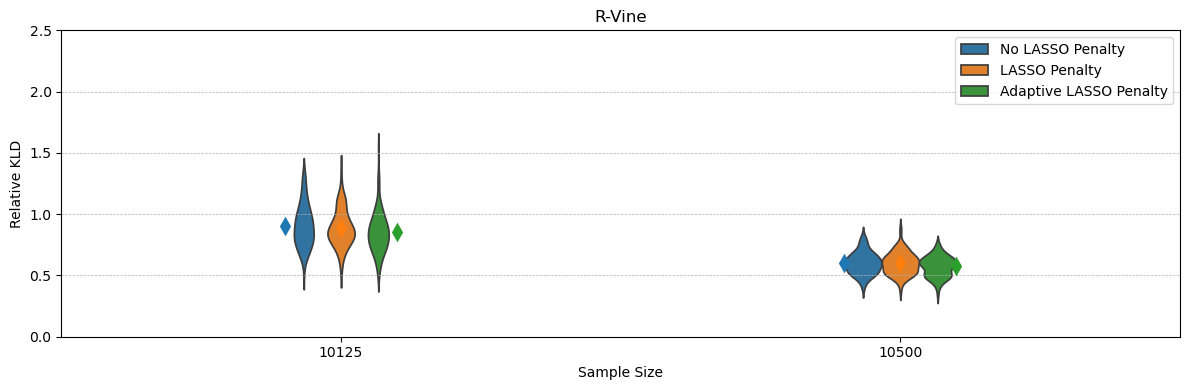

In [18]:
create_comparison_violin_plot(
    kld_no,
    kld_lasso,
    kld_adaptive,
    metric = "rel_kld_test",
    sample_sizes = [125, 500],
    experiment_strings=experiment_name_list,
    y_min = 0.,
    y_max = 2.5,
    legend=True,
    metric_str="Relative KLD"
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

## AUC Results

### R-Vine

In [35]:
# Usage:
experiment_name_list = ["rvine_10D_125obs"]
auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(experiment_name_list)

In [29]:
experiment_name_list = ["rvine_10D_125obs","rvine_10D_500obs","rvine_10D_2000obs"]
auc_ggm = {}
for experiment_name in experiment_name_list:
    auc_ggm[experiment_name] = np.load('simulation_studies/ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy')

In [105]:
auc_no["rvine_10D_125obs"].keys()

dict_keys(['metrics.auc_loglik_diff_data', 'metrics.auc_normed_hessian_val', 'metrics.auc_cond_corr_train', 'metrics.auc_cond_corr_data', 'metrics.auc_cond_corr_val', 'metrics.auc_loglik_diff_train', 'metrics.auc_precision_matrix_train', 'metrics.auc_normed_hessian_data', 'metrics.auc_cond_corr', 'metrics.auc_precision_matrix_data', 'metrics.auc_precision_matrix_val', 'metrics.auc_normed_hessian_train', 'metrics.auc_loglik_diff_val', 'metrics.auc_precision_matrix', 'metrics.auc_iae', 'metrics.auc_normed_hessian', 'metrics.auc_kld'])

In [85]:
np.mean(auc_ggm["rvine_10D_2000obs"])

0.9027579365079365

In [86]:
np.mean(auc_ggm["rvine_10D_10000obs"])

0.9085416666666668

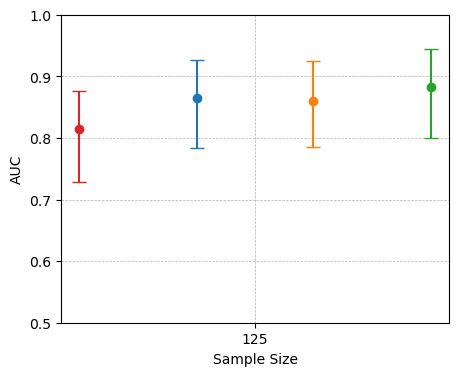

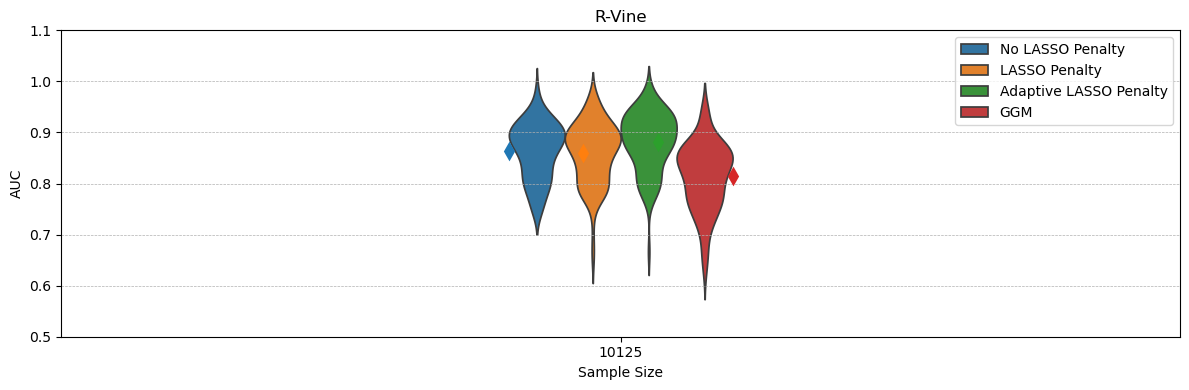

In [37]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian_data",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
    benchmark=auc_ggm,
    lower_quantile=10,
    upper_quantile=90,
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian_data",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
    benchmark=auc_ggm,
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

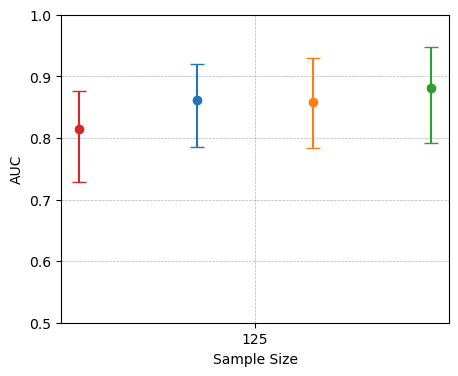

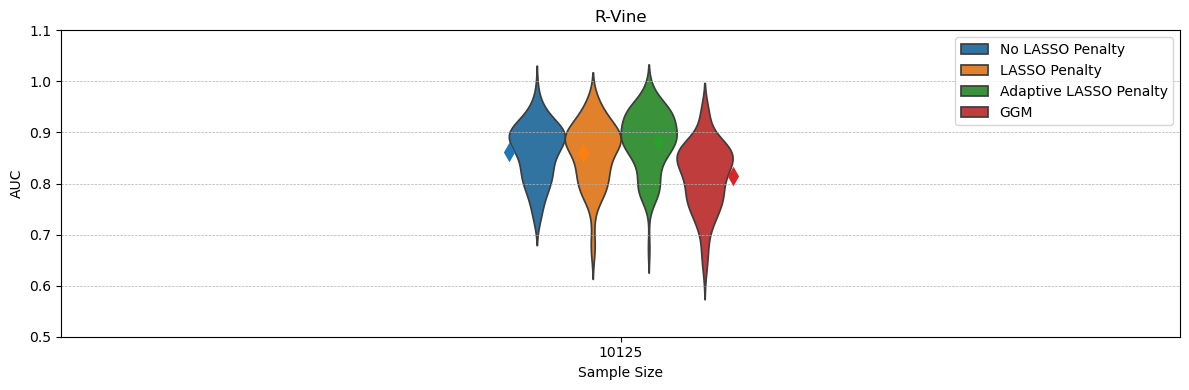

In [43]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
    benchmark=auc_ggm,
    lower_quantile=10,
    upper_quantile=90
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
    benchmark=auc_ggm,
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

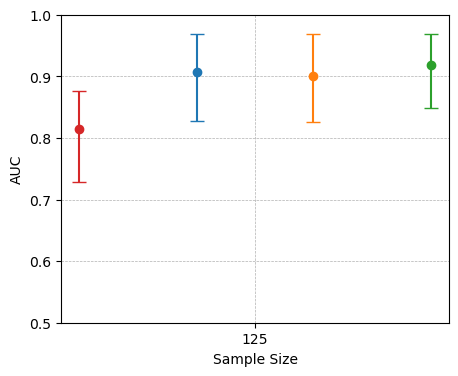

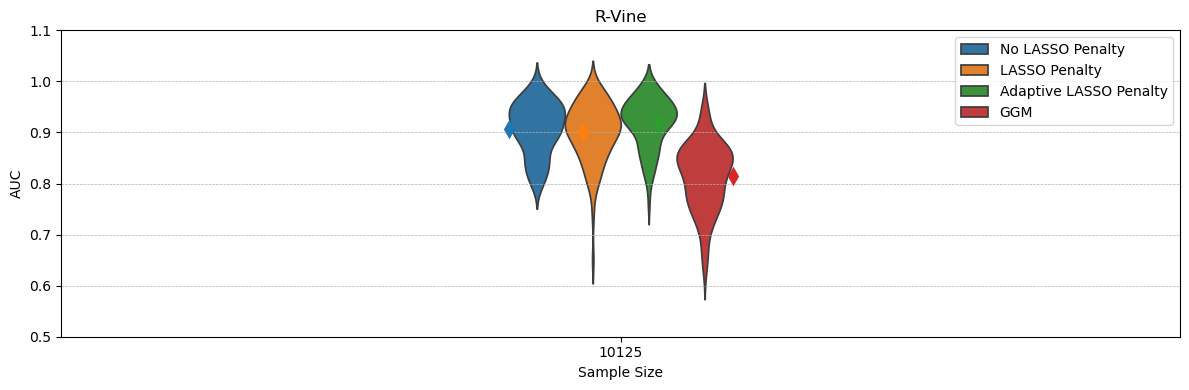

In [45]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_iae",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
    benchmark=auc_ggm,
    lower_quantile=10,
    upper_quantile=90
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_iae",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
    benchmark=auc_ggm,
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

#### 20D R-Vine

In [47]:
# Usage:
experiment_name_list = ["rvine_20D_2000obs"]
auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(experiment_name_list, seed_max=24,seed_min=0)

In [ ]:
for key in list(auc_no.keys()):
    for key2 in list(auc_no[key].keys()):
        print(np.mean((np.array(auc_dict_adaptive_2[key][key2]) - np.array(auc_adaptive[key][key2]))>0))

0.52
0.52
0.44
0.48
0.52
0.44
0.48
0.48
0.6
0.56
0.6
0.68
0.48
0.56
0.36
0.44
0.56


In [ ]:
# Usage:
experiment_name_list = ["rvine_strong_10D_125obs_copulaonly"]
kld_dict_no, kld_dict_lasso, kld_dict_adaptive, kld_dict_adaptive_2 = get_kld_dicts(experiment_name_list, seed_max=24,seed_min=0)

there are nan values in rel_kld_test, the number is  1


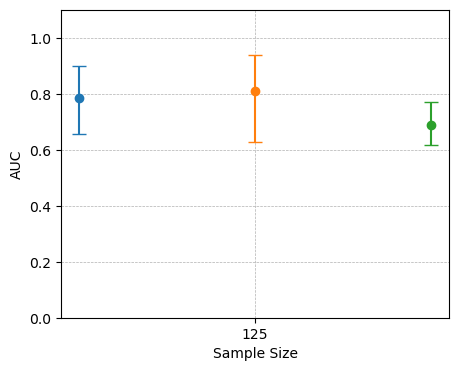

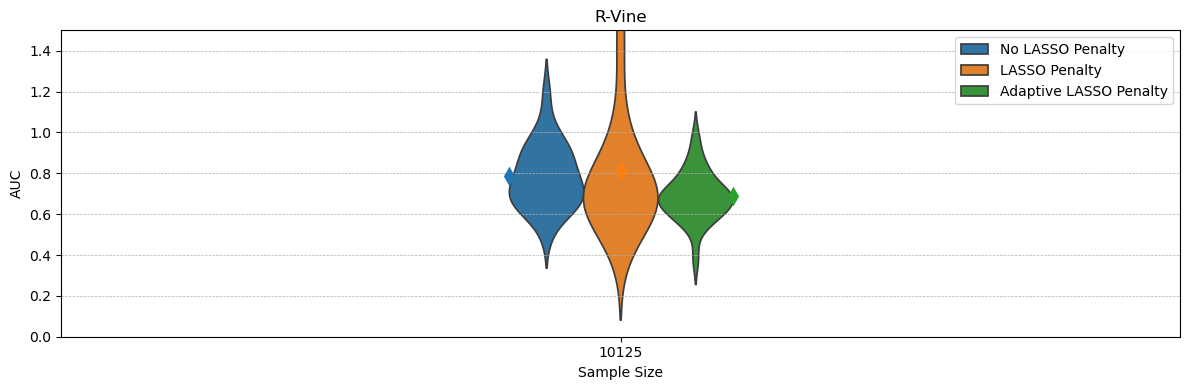

In [ ]:
create_comparison_plot_one_scenario(
    kld_dict_no,
    kld_dict_adaptive_2,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.1,
)

create_comparison_violin_plot(
    kld_dict_no,
    kld_dict_adaptive_2,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.5,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_normed_hessian, the number is  1


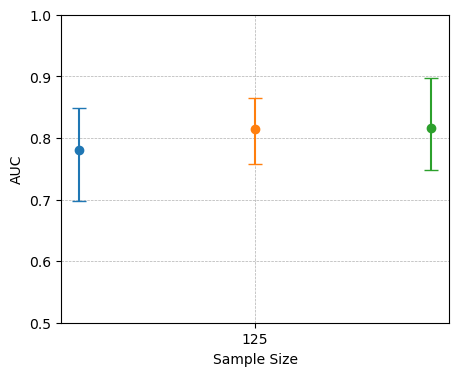

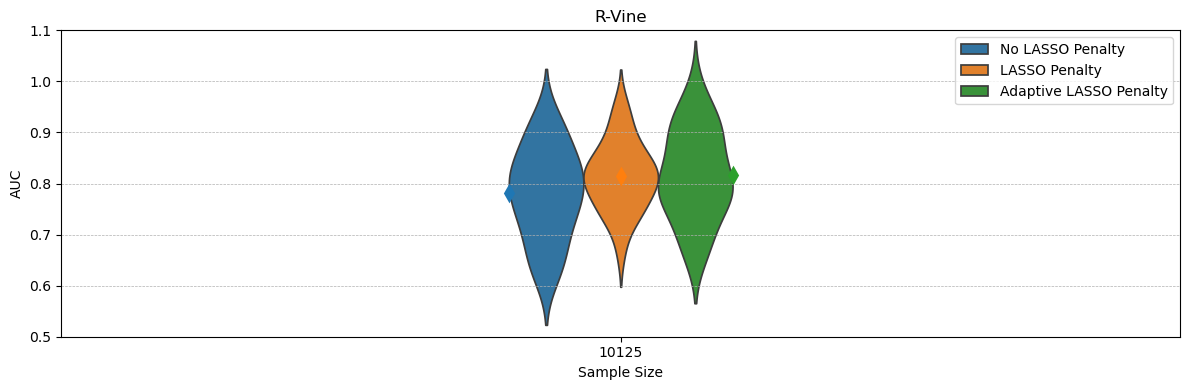

In [ ]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_iae, the number is  1


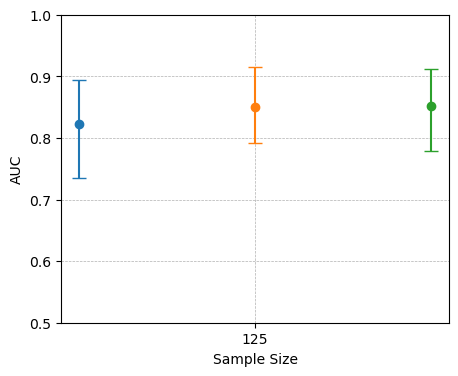

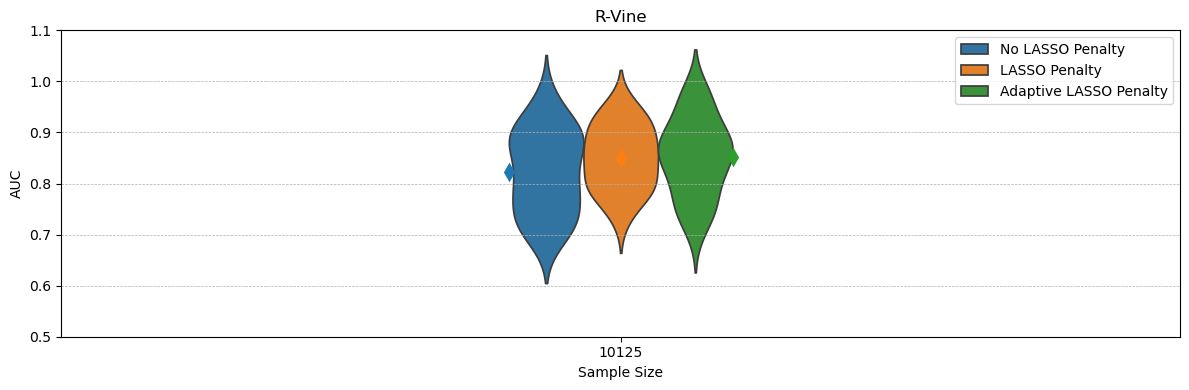

In [ ]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_iae",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_iae",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_cond_corr, the number is  1


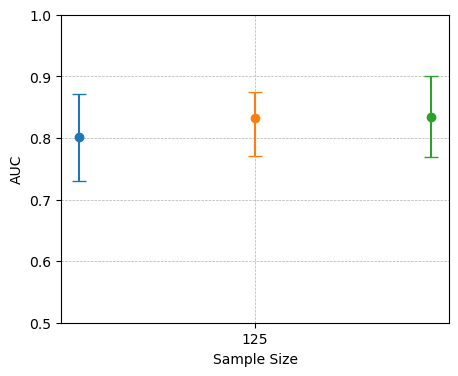

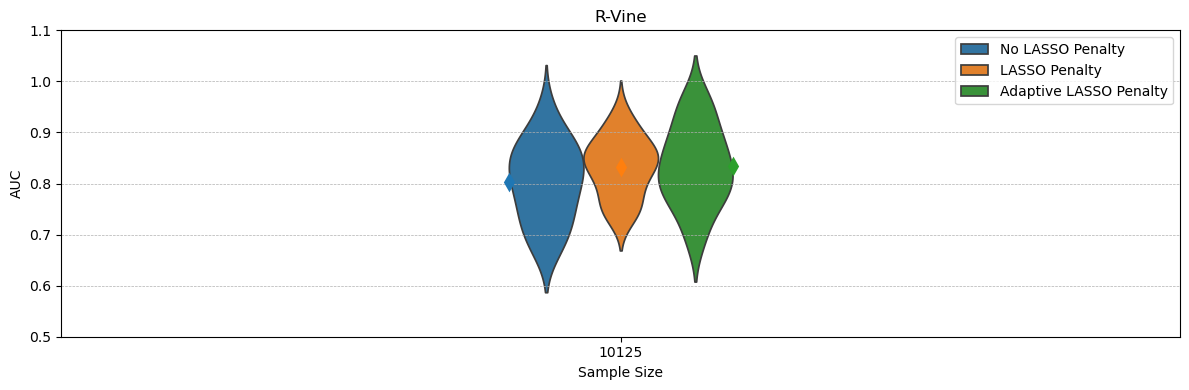

In [ ]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

### D-Vine

In [142]:
# Usage:
experiment_name_list = ["dvine_10D_125obs", "dvine_10D_500obs", "dvine_10D_2000obs"]
auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(experiment_name_list, seed_min=0, seed_max=50)#24)

In [143]:
auc_ggm = {}
for experiment_name in experiment_name_list:
    auc_ggm[experiment_name] = np.load('simulation_studies/ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy')

there are nan values in metrics.auc_normed_hessian_data, the number is  1


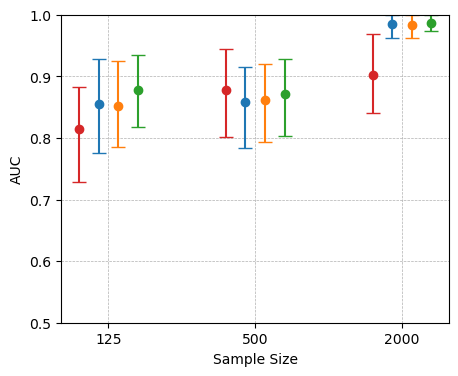

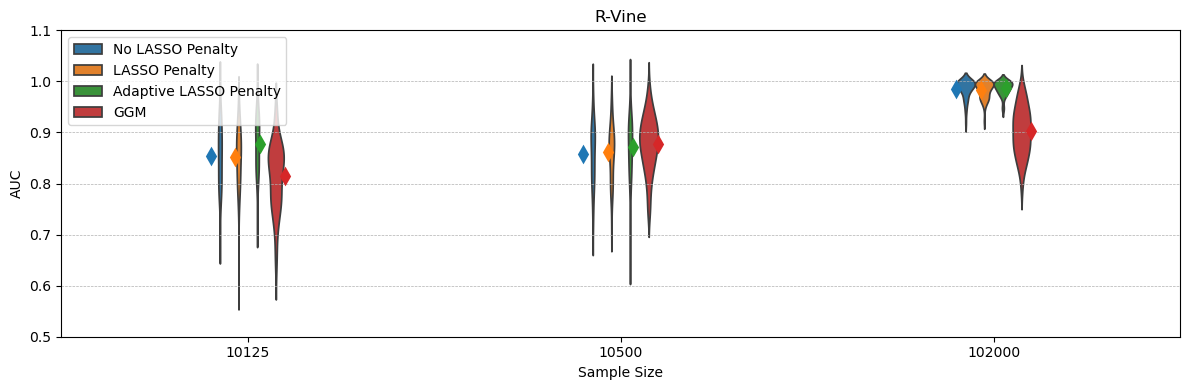

In [141]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian_data",
    title_str = "D-Vine",
    sample_sizes = [125, 500, 2000],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
    benchmark=auc_ggm,
    lower_quantile=10,
    upper_quantile=90
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian_data",
    sample_sizes = [125, 500, 2000],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
    benchmark=auc_ggm
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_normed_hessian, the number is  1


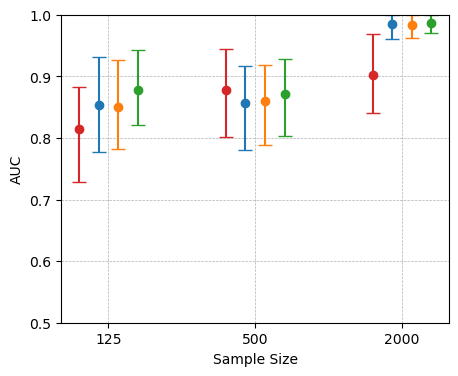

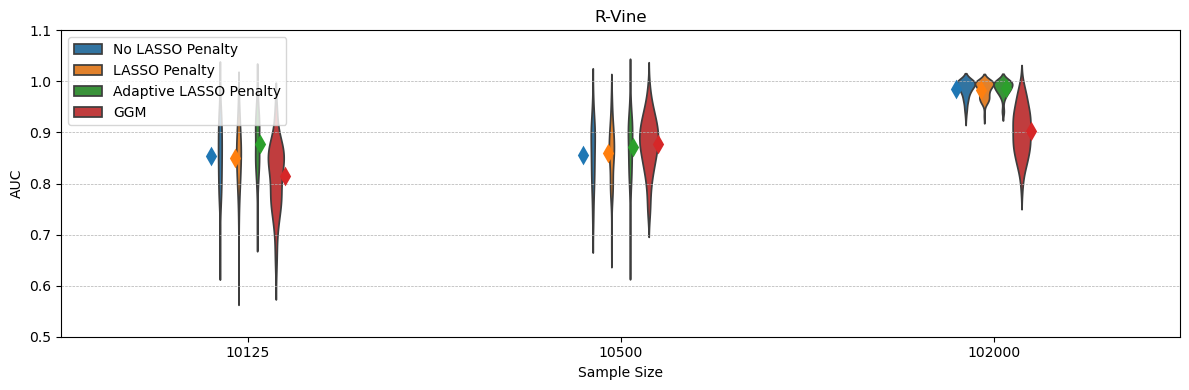

In [139]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    title_str = "D-Vine",
    sample_sizes = [125, 500, 2000],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
    benchmark=auc_ggm,
    lower_quantile=10,
    upper_quantile=90
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    sample_sizes = [125, 500, 2000],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
    benchmark=auc_ggm
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_iae, the number is  1


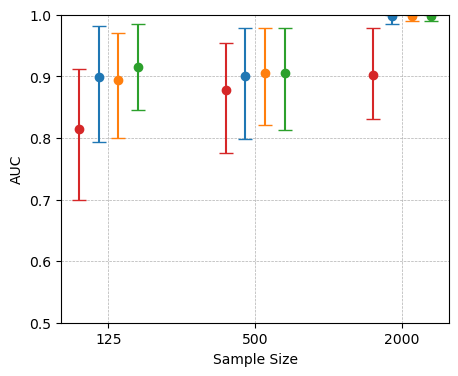

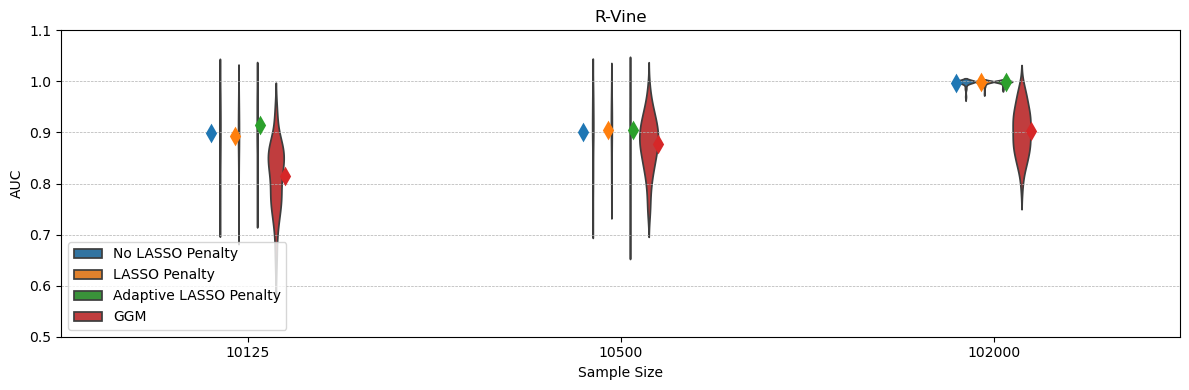

In [136]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_iae",
    title_str = "D-Vine",
    sample_sizes = [125, 500, 2000],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
    benchmark=auc_ggm,
    lower_quantile=5,
    upper_quantile=95
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_iae",
    sample_sizes = [125, 500, 2000],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
    benchmark=auc_ggm
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

### C-Vine

In [17]:
# Usage:
experiment_name_list = ["cvine_10D_125obs", "cvine_10D_500obs"]
auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(experiment_name_list)

In [ ]:
auc_ggm = {}
for experiment_name in experiment_name_list:
    auc_ggm[experiment_name] = np.load('simulation_studies/ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy')

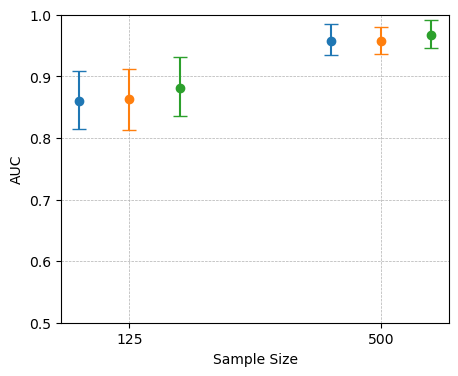

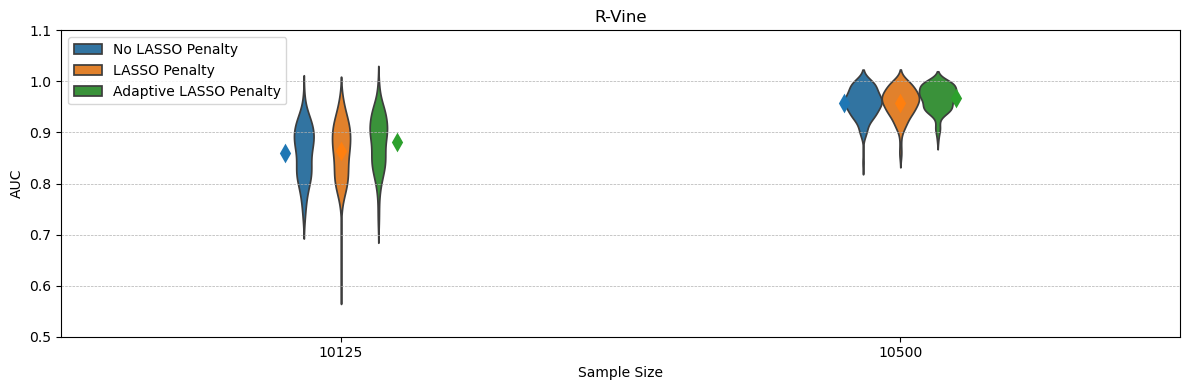

In [ ]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian_data",
    title_str = "R-Vine",
    sample_sizes = [125, 500],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
    benchmark=auc_ggm
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian_data",
    sample_sizes = [125, 500],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
    benchmark=auc_ggm
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

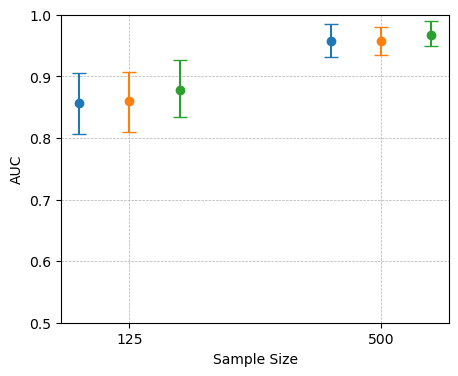

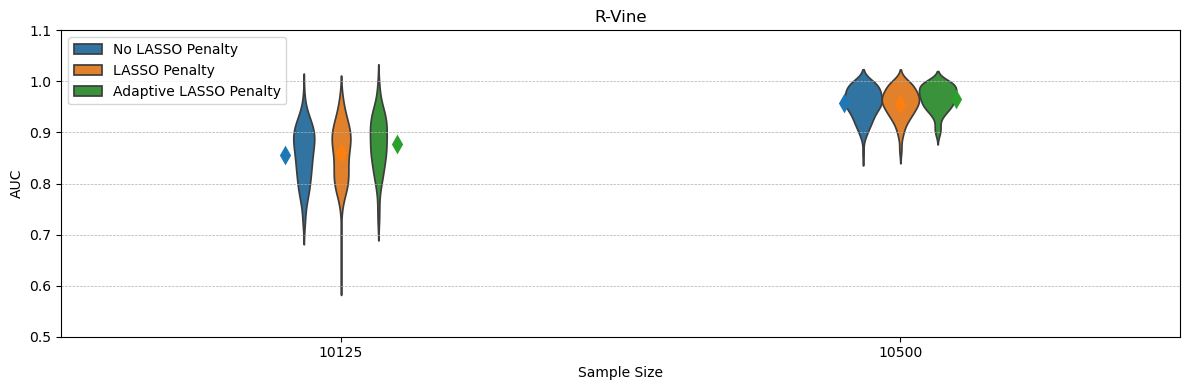

In [ ]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    title_str = "R-Vine",
    sample_sizes = [125, 500],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
    benchmark=auc_ggm
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    sample_sizes = [125, 500],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
    benchmark=auc_ggm
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

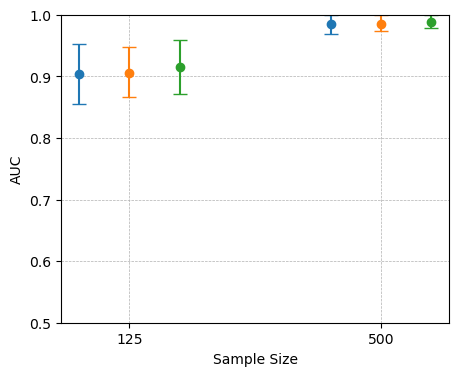

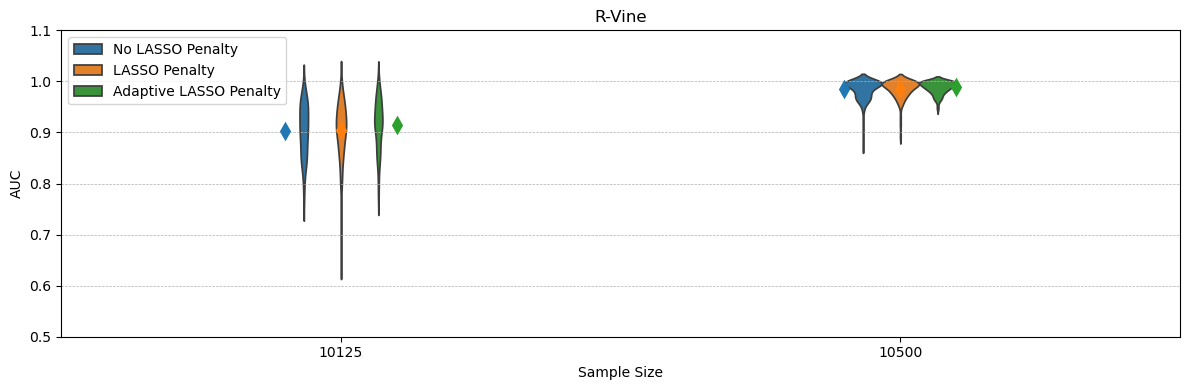

In [ ]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_iae",
    title_str = "R-Vine",
    sample_sizes = [125, 500],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
    benchmark=auc_ggm
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_iae",
    sample_sizes = [125, 500],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
    benchmark=auc_ggm
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

## AUC Results Strong

#### cvine

In [63]:
# Usage:
experiment_name_list = ["cvine_strong_10D_125obs_copulaonly"]
auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(experiment_name_list, seed_max=49,seed_min=0)

In [64]:
# Usage:
experiment_name_list = ["cvine_strong_10D_125obs_copulaonly"]
kld_dict_no, kld_dict_lasso, kld_dict_adaptive = get_kld_dicts(experiment_name_list, seed_max=49,seed_min=0)

there are nan values in rel_kld_test, the number is  1
there are nan values in rel_kld_test, the number is  1


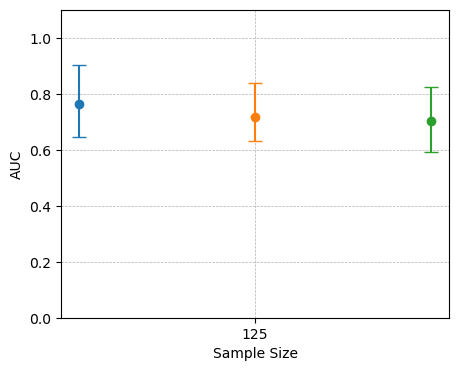

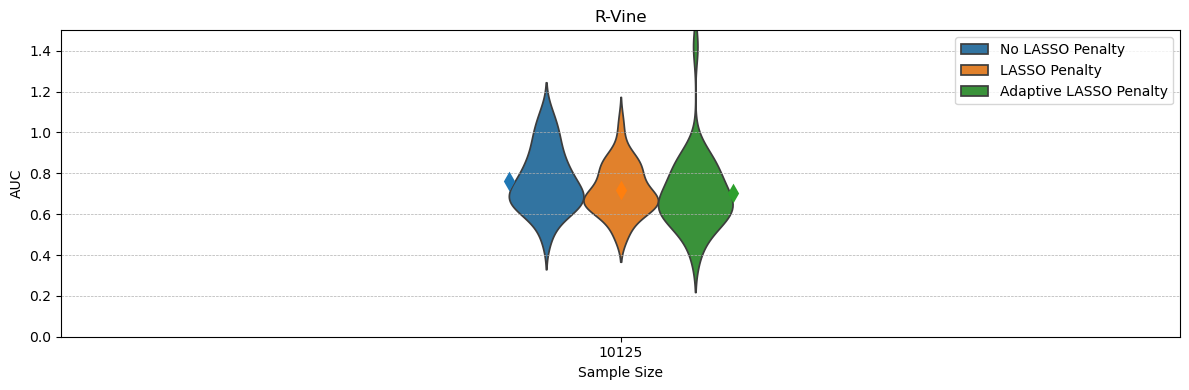

In [65]:
create_comparison_plot_one_scenario(
    kld_dict_no,
    kld_dict_lasso,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.1,
)

create_comparison_violin_plot(
    kld_dict_no,
    kld_dict_lasso,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.5,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in metrics.auc_normed_hessian, the number is  1


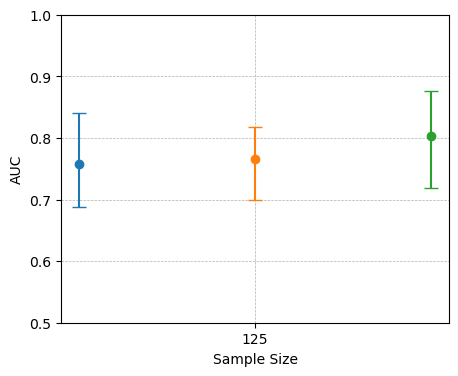

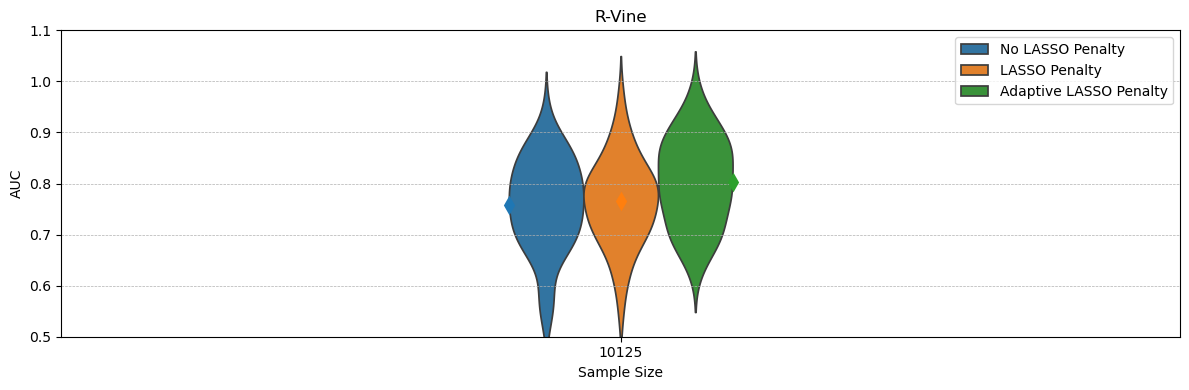

In [66]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_iae, the number is  1


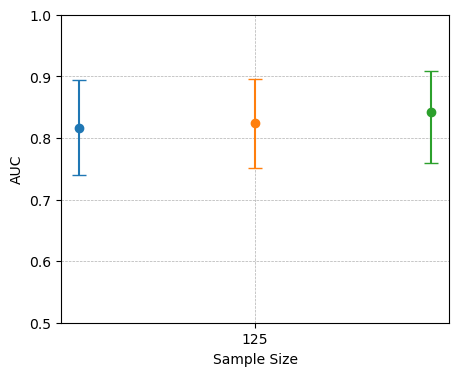

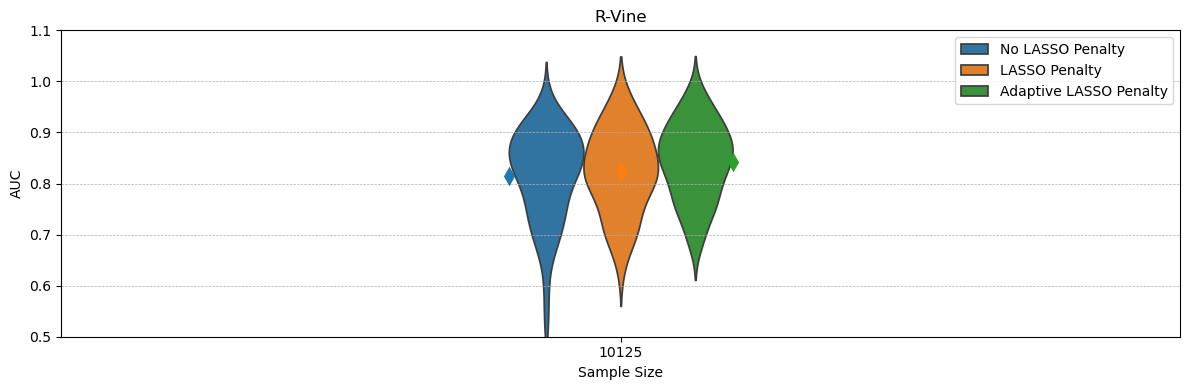

In [67]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_iae",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_iae",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_cond_corr, the number is  1
there are nan values in metrics.auc_cond_corr, the number is  1


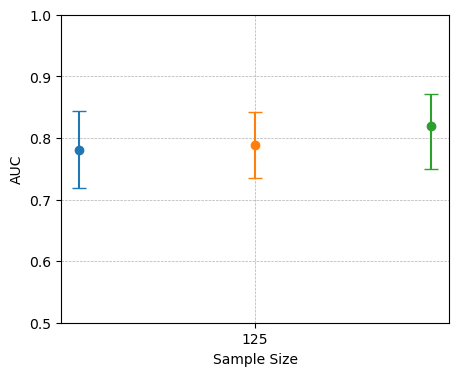

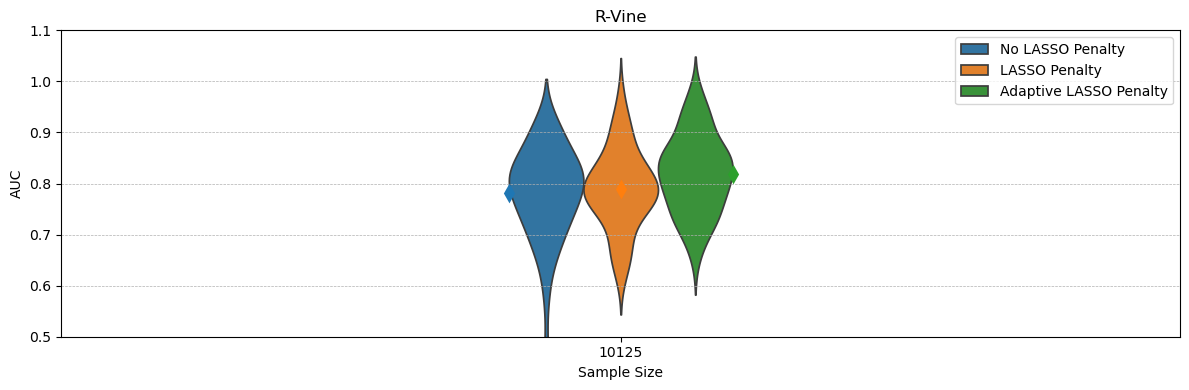

In [68]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

#### dvine

In [69]:
# Usage:
experiment_name_list = ["dvine_strong_10D_125obs_copulaonly"]
auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(experiment_name_list, seed_max=49,seed_min=0)

In [70]:
# Usage:
experiment_name_list = ["dvine_strong_10D_125obs_copulaonly"]
kld_dict_no, kld_dict_lasso, kld_dict_adaptive = get_kld_dicts(experiment_name_list, seed_max=49,seed_min=0)

there are nan values in rel_kld_test, the number is  2
there are nan values in rel_kld_test, the number is  1


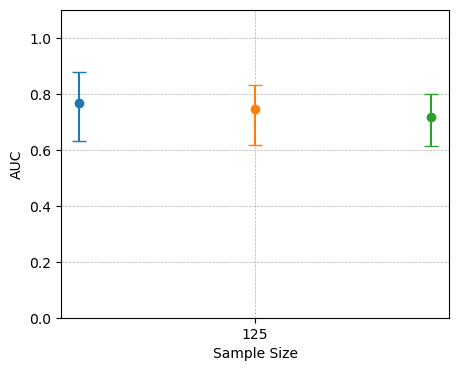

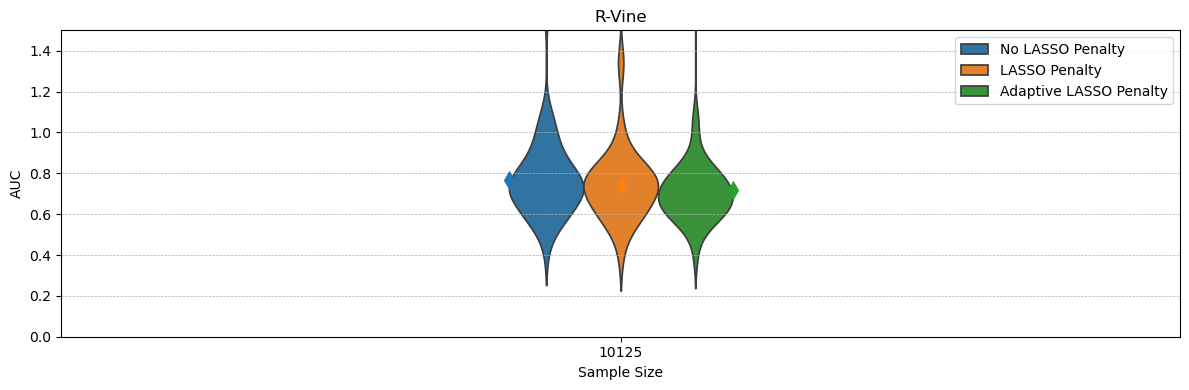

In [71]:
create_comparison_plot_one_scenario(
    kld_dict_no,
    kld_dict_lasso,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.1,
)

create_comparison_violin_plot(
    kld_dict_no,
    kld_dict_lasso,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.5,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_normed_hessian, the number is  2
there are nan values in metrics.auc_normed_hessian, the number is  1


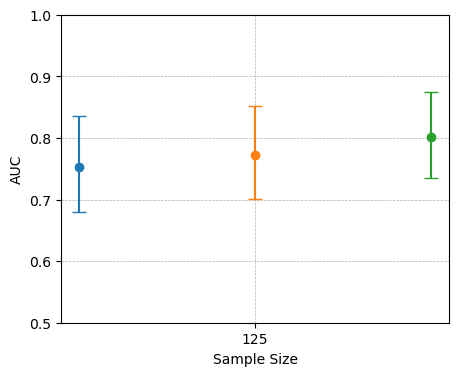

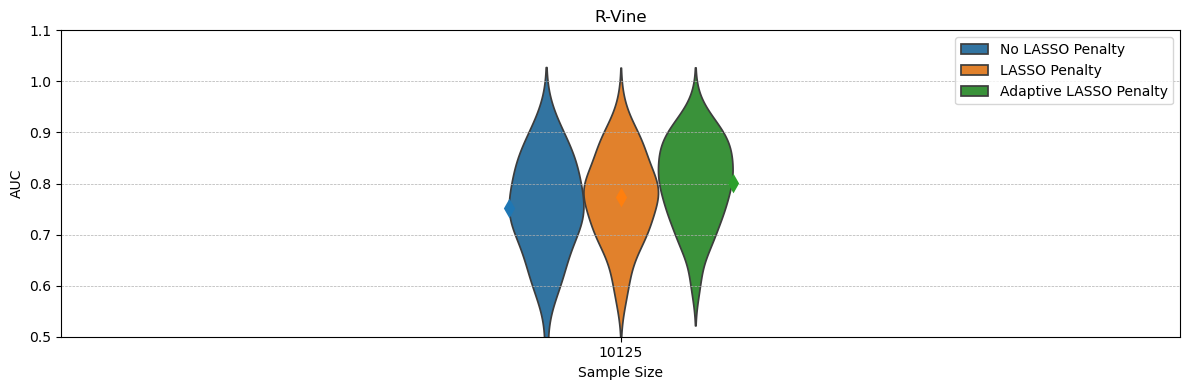

In [72]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_iae, the number is  2
there are nan values in metrics.auc_iae, the number is  1


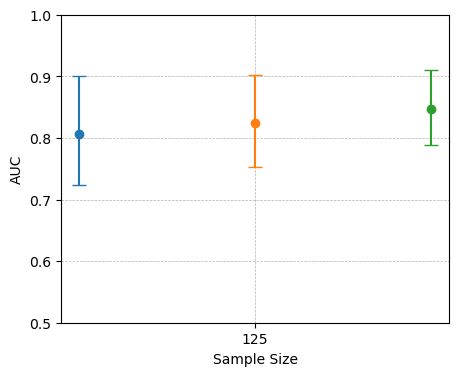

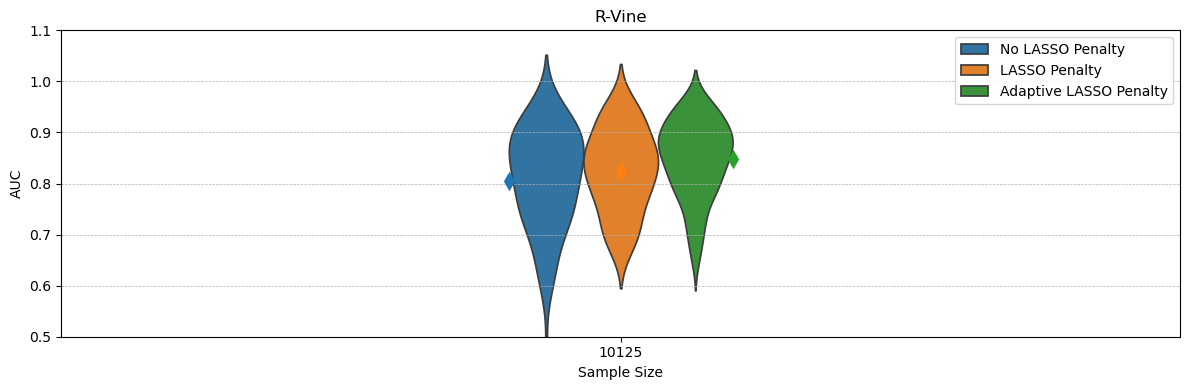

In [73]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_iae",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_iae",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_cond_corr, the number is  2
there are nan values in metrics.auc_cond_corr, the number is  1


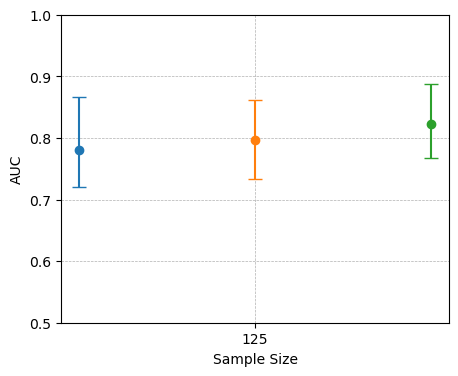

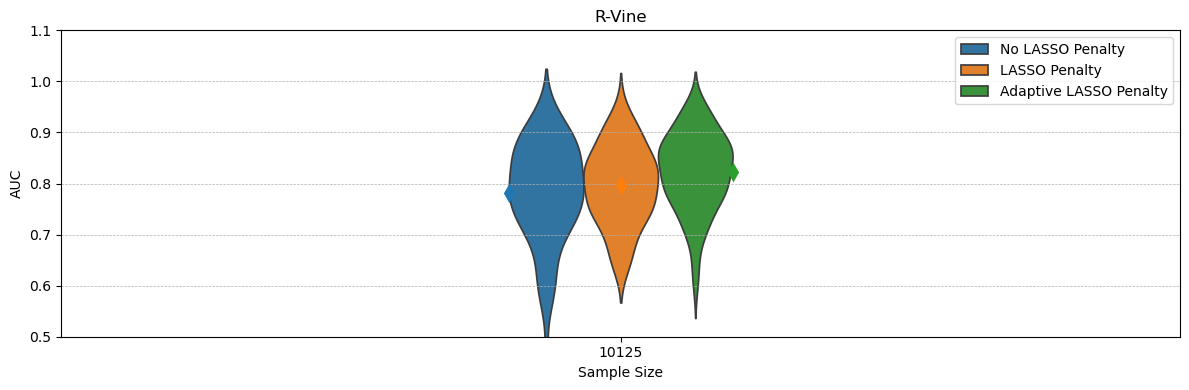

In [74]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

#### rvine

In [75]:
# Usage:
experiment_name_list = ["rvine_strong_10D_125obs_copulaonly"]
auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(experiment_name_list, seed_max=49,seed_min=0)

In [76]:
# Usage:
experiment_name_list = ["rvine_strong_10D_125obs_copulaonly"]
kld_dict_no, kld_dict_lasso, kld_dict_adaptive = get_kld_dicts(experiment_name_list, seed_max=49,seed_min=0)

there are nan values in rel_kld_test, the number is  1
there are nan values in rel_kld_test, the number is  1


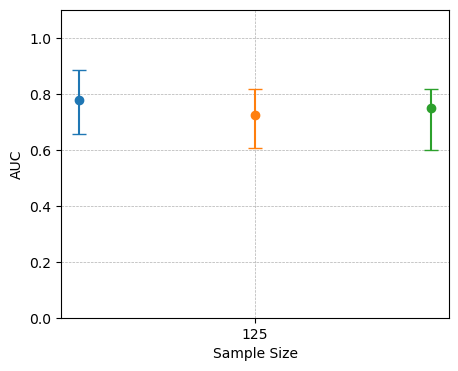

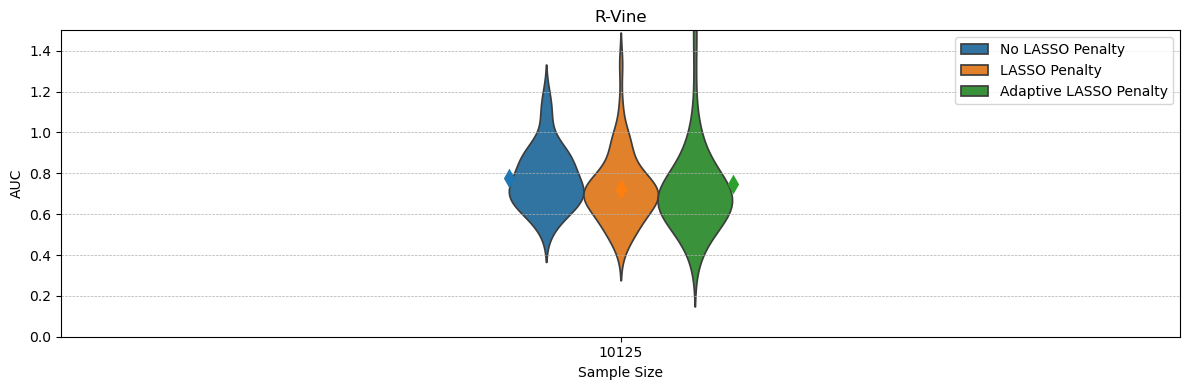

In [77]:
create_comparison_plot_one_scenario(
    kld_dict_no,
    kld_dict_lasso,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.1,
)

create_comparison_violin_plot(
    kld_dict_no,
    kld_dict_lasso,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.5,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in metrics.auc_normed_hessian, the number is  1


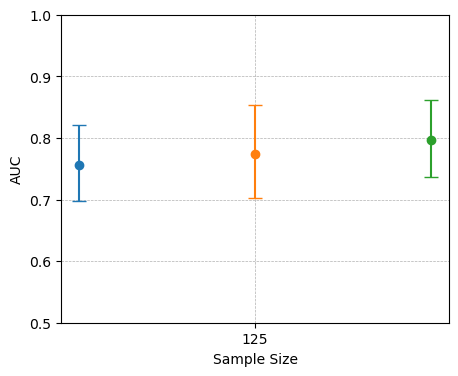

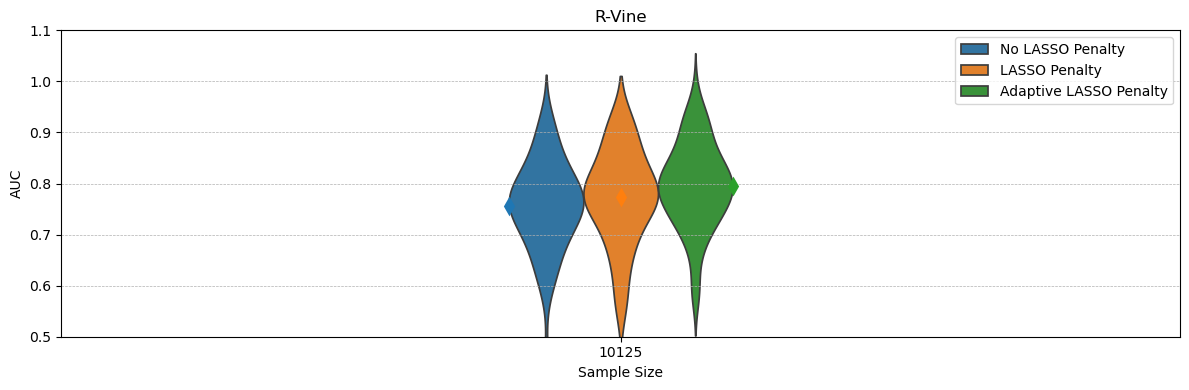

In [78]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_iae, the number is  1


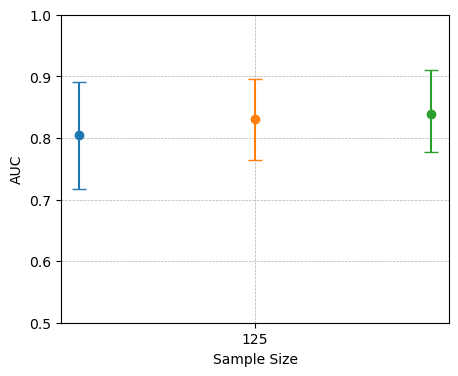

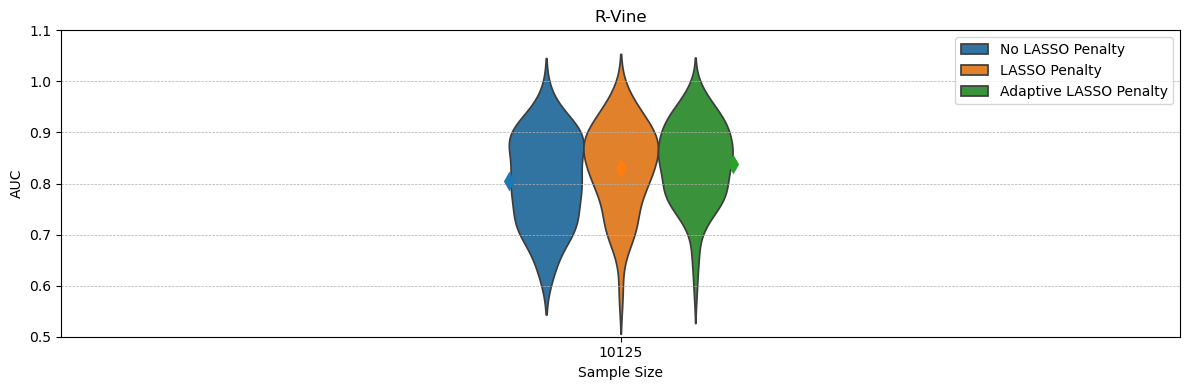

In [79]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_iae",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_iae",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_cond_corr, the number is  1
there are nan values in metrics.auc_cond_corr, the number is  1


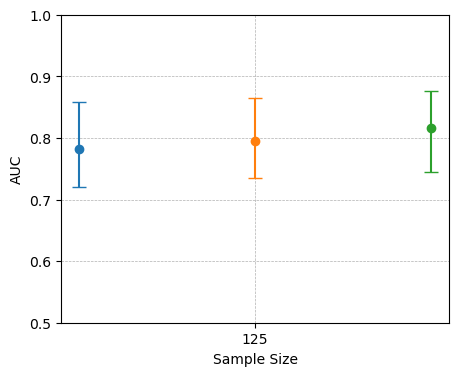

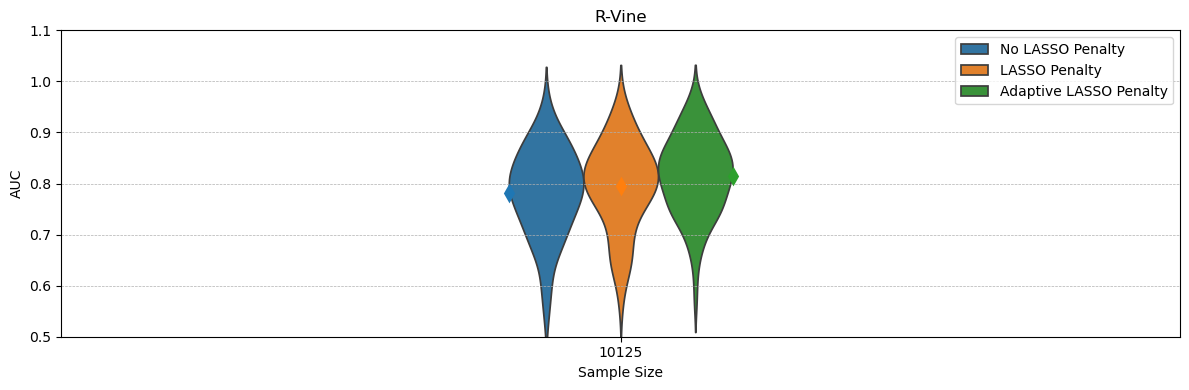

In [80]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_lasso,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

## AUC Results Strong with adaptive 2

#### cvine

In [10]:
def get_auc_dicts_all(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    print_run_names=False
):
    auc_dict_no = {}
    auc_dict_lasso = {}
    auc_dict_adaptive = {}
    auc_dict_adaptive_2 = {}

    configs = [
        ("No",      ["Adaptive", "Lasso", "Adaptive_2"],     auc_dict_no),
        ("Lasso",   ["Adaptive", "No", "Adaptive_2"],        auc_dict_lasso),
        ("Adaptive",["Lasso", "No", "Adaptive_2"],           auc_dict_adaptive),
        ("Adaptive_2",["Lasso", "No"],           auc_dict_adaptive_2)
    ]
    for name_look_for, name_not_look_for, result_dict in configs:
        for experiment_name in experiment_name_list:
            result_dict[experiment_name] = get_auc_across_metrics_experiment(
                experiment_name=experiment_name,
                name_ending_look_for=name_look_for,
                name_endings_not_look_for_list=name_not_look_for,
                seed_min=seed_min,
                seed_max=seed_max,
                print_run_names=print_run_names
            )
            
    return auc_dict_no, auc_dict_lasso, auc_dict_adaptive,auc_dict_adaptive_2


In [11]:
def get_kld_dicts(experiment_name_list, seed_min=0, seed_max=99, kld_available=False, print_info=False, print_run_names=False, copula=False):
    rvine_kld_dict_no = {}
    rvine_kld_dict_lasso = {}
    rvine_kld_dict_adaptive = {}
    rvine_kld_dict_adaptive_2 = {}
    # Config for each type
    configs = [
        ("No",      ["Adaptive", "Lasso", "Adaptive_2"],     rvine_kld_dict_no),
        ("Lasso",   ["Adaptive", "No", "Adaptive_2"],        rvine_kld_dict_lasso),
        ("Adaptive",["Lasso", "No", "Adaptive_2"],           rvine_kld_dict_adaptive),
        ("Adaptive_2",["Lasso", "No"],           rvine_kld_dict_adaptive_2)
    ]
    for name_ending_look_for, name_endings_not_look_for_list, result_dict in configs:
        for experiment_name in experiment_name_list:
            result_dict[experiment_name] = get_rel_kld_experiment(
                experiment_name=experiment_name,
                name_ending_look_for=name_ending_look_for,
                name_endings_not_look_for_list=name_endings_not_look_for_list,
                seed_min=seed_min,
                seed_max=seed_max,
                kld_available=kld_available,
                print_info=print_info,
                print_run_names=print_run_names,
                copula=copula
            )
    return rvine_kld_dict_no, rvine_kld_dict_lasso, rvine_kld_dict_adaptive, rvine_kld_dict_adaptive_2

In [12]:
# Usage:
experiment_name_list = ["cvine_strong_10D_125obs_copulaonly"]
auc_no, auc_lasso, auc_adaptive, auc_dict_adaptive_2 = get_auc_dicts_all(experiment_name_list, seed_max=15,seed_min=0)

In [13]:
# Usage:
experiment_name_list = ["cvine_strong_10D_125obs_copulaonly"]
kld_dict_no, kld_dict_lasso, kld_dict_adaptive, kld_dict_adaptive_2 = get_kld_dicts(experiment_name_list, seed_max=15,seed_min=0)

there are nan values in rel_kld_test, the number is  1


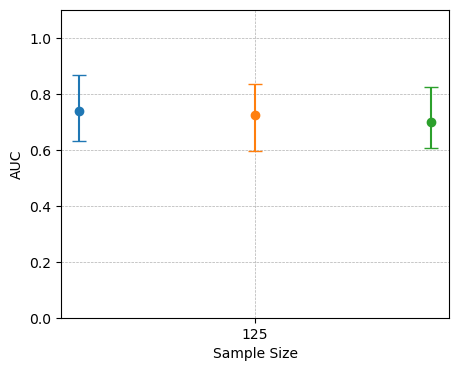

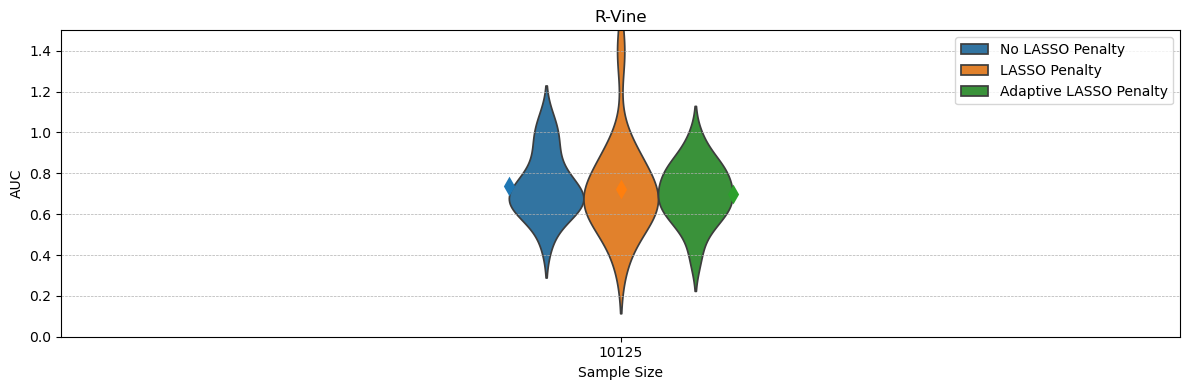

In [14]:
create_comparison_plot_one_scenario(
    kld_dict_no,
    kld_dict_adaptive_2,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.1,
)

create_comparison_violin_plot(
    kld_dict_no,
    kld_dict_adaptive_2,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.5,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

In [15]:
for key in list(auc_adaptive.keys()):
    for key2 in list(auc_adaptive[key].keys()):
        print(np.mean((np.array(auc_dict_adaptive_2[key][key2]) - np.array(auc_adaptive[key][key2]))>0))

0.625
0.75
0.8125
0.8125
0.875
0.625
0.75
0.8125
0.75
0.75
0.625
0.8125
0.5625
0.625
0.625
0.75
0.5625


there are nan values in metrics.auc_normed_hessian, the number is  1


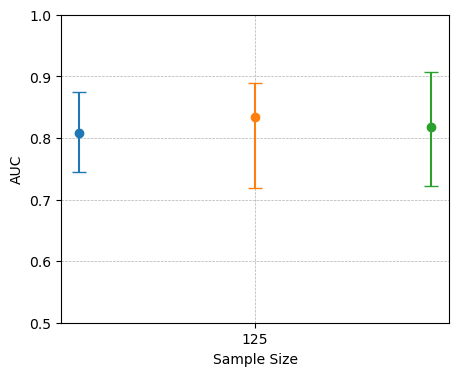

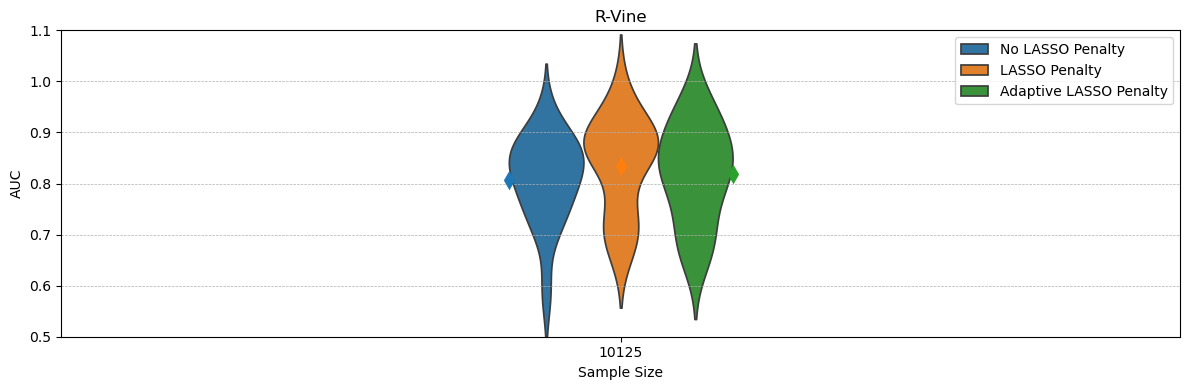

In [16]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_iae, the number is  1


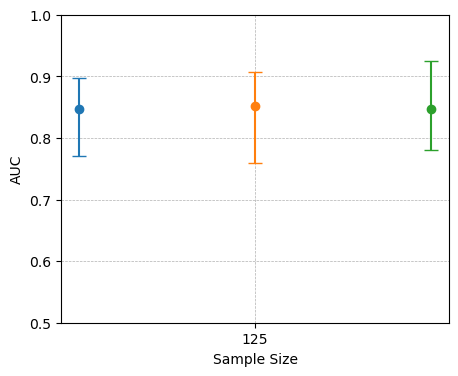

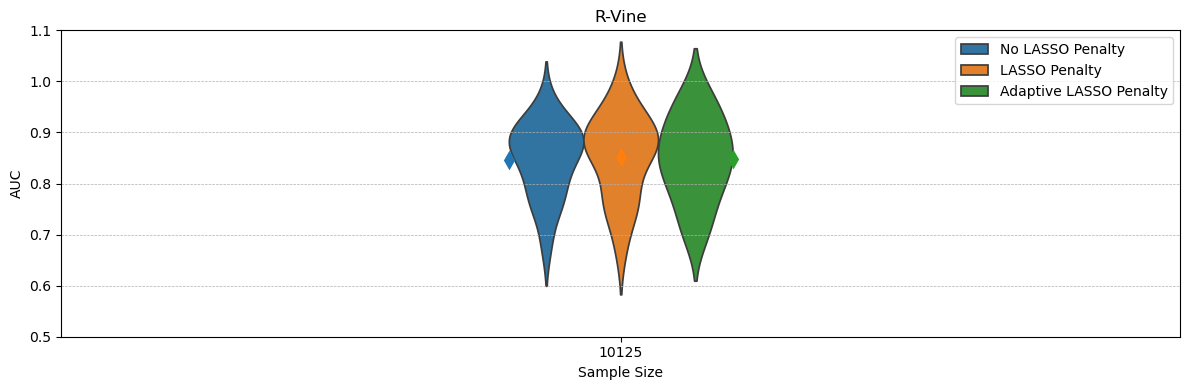

In [17]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_iae",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_iae",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_cond_corr, the number is  1


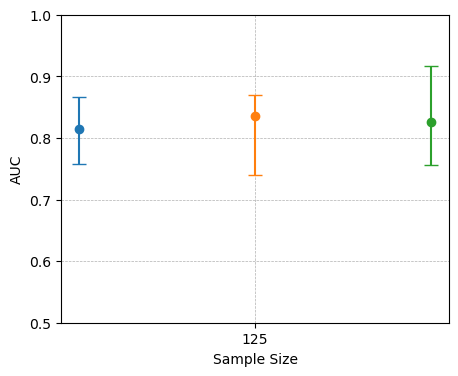

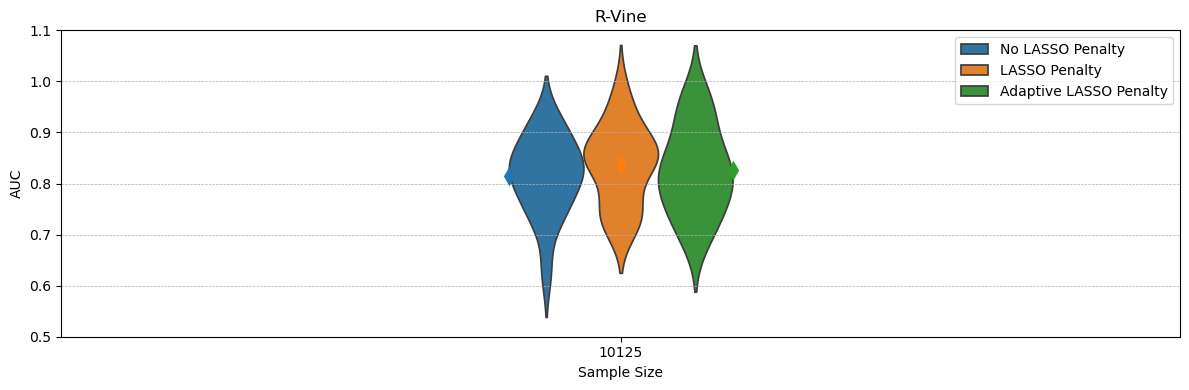

In [18]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

#### dvine

In [33]:
# Usage:
experiment_name_list = ["dvine_strong_10D_125obs_copulaonly"]
auc_no, auc_lasso, auc_adaptive, auc_dict_adaptive_2 = get_auc_dicts_all(experiment_name_list, seed_max=35,seed_min=0)

In [34]:
for key in list(auc_no.keys()):
    for key2 in list(auc_no[key].keys()):
        print(np.mean((np.array(auc_dict_adaptive_2[key][key2]) - np.array(auc_adaptive[key][key2]))>0))

0.4166666666666667
0.5555555555555556
0.5555555555555556
0.5555555555555556
0.5555555555555556
0.4166666666666667
0.5833333333333334
0.5277777777777778
0.5555555555555556
0.5833333333333334
0.5833333333333334
0.5277777777777778
0.3888888888888889
0.5833333333333334
0.5277777777777778
0.4722222222222222
0.5277777777777778


In [35]:
# Usage:
experiment_name_list = ["dvine_strong_10D_125obs_copulaonly"]
kld_dict_no, kld_dict_lasso, kld_dict_adaptive, kld_dict_adaptive_2 = get_kld_dicts(experiment_name_list, seed_max=35,seed_min=0)

there are nan values in rel_kld_test, the number is  2


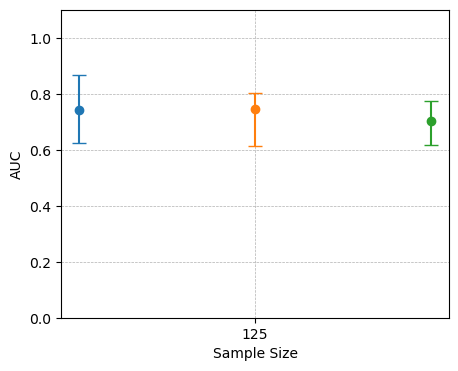

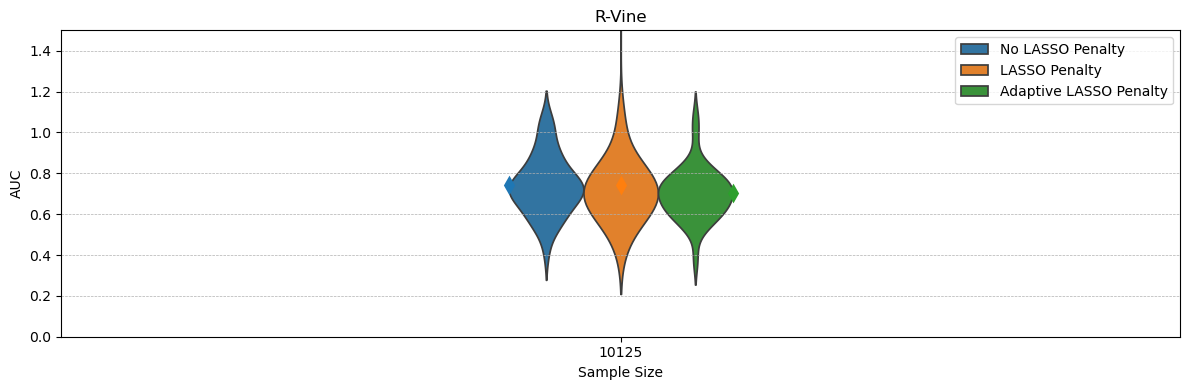

In [36]:
create_comparison_plot_one_scenario(
    kld_dict_no,
    kld_dict_adaptive_2,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.1,
)

create_comparison_violin_plot(
    kld_dict_no,
    kld_dict_adaptive_2,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.5,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_normed_hessian, the number is  2


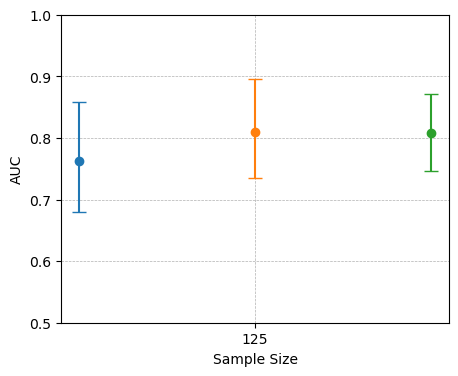

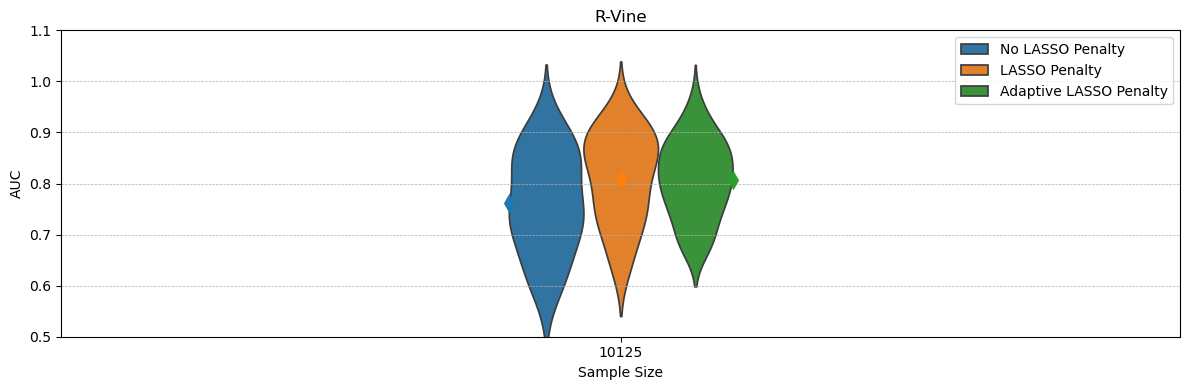

In [37]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_iae, the number is  2


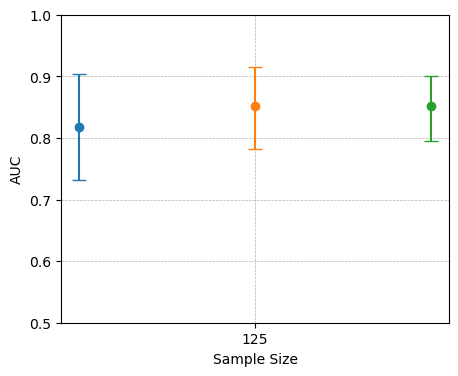

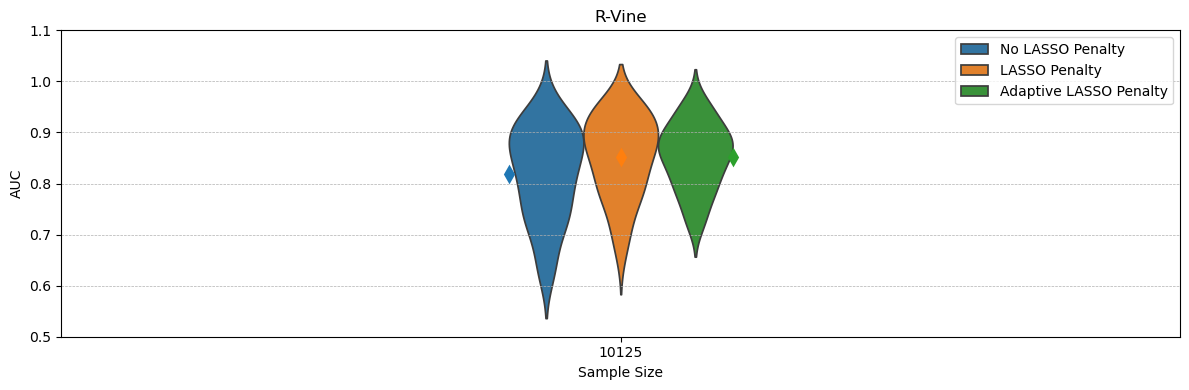

In [38]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_iae",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_iae",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_cond_corr, the number is  2


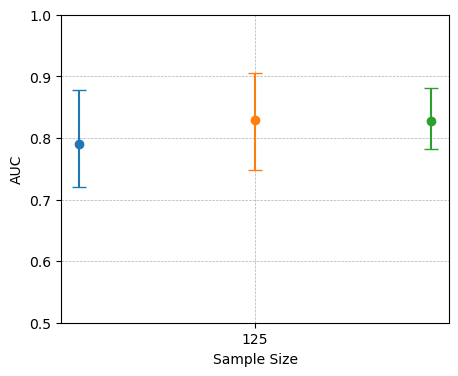

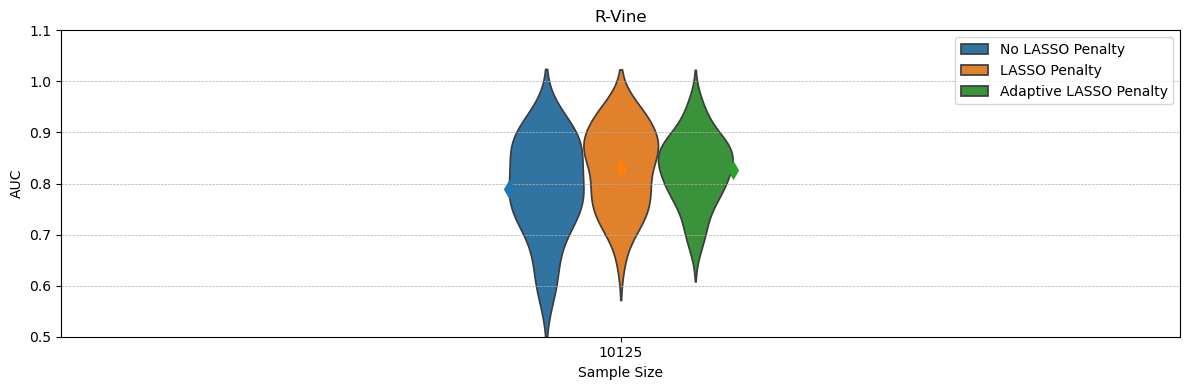

In [39]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

#### rvine

In [40]:
# Usage:
experiment_name_list = ["rvine_strong_10D_125obs_copulaonly"]
auc_no, auc_lasso, auc_adaptive, auc_dict_adaptive_2 = get_auc_dicts_all(experiment_name_list, seed_max=35,seed_min=0)

In [41]:
for key in list(auc_no.keys()):
    for key2 in list(auc_no[key].keys()):
        print(np.mean((np.array(auc_dict_adaptive_2[key][key2]) - np.array(auc_adaptive[key][key2]))>0))

0.5833333333333334
0.5833333333333334
0.5555555555555556
0.5555555555555556
0.5277777777777778
0.5833333333333334
0.4722222222222222
0.6111111111111112
0.5277777777777778
0.4722222222222222
0.5
0.6111111111111112
0.5
0.3888888888888889
0.5
0.5277777777777778
0.6666666666666666


In [42]:
# Usage:
experiment_name_list = ["rvine_strong_10D_125obs_copulaonly"]
kld_dict_no, kld_dict_lasso, kld_dict_adaptive, kld_dict_adaptive_2 = get_kld_dicts(experiment_name_list, seed_max=35,seed_min=0)

there are nan values in rel_kld_test, the number is  1


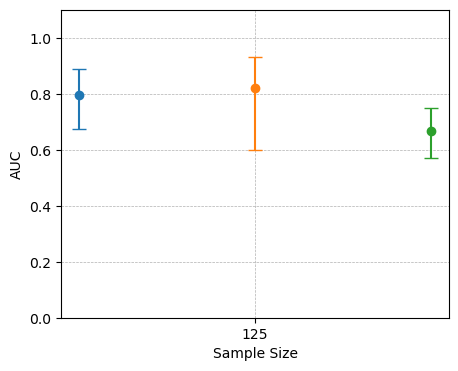

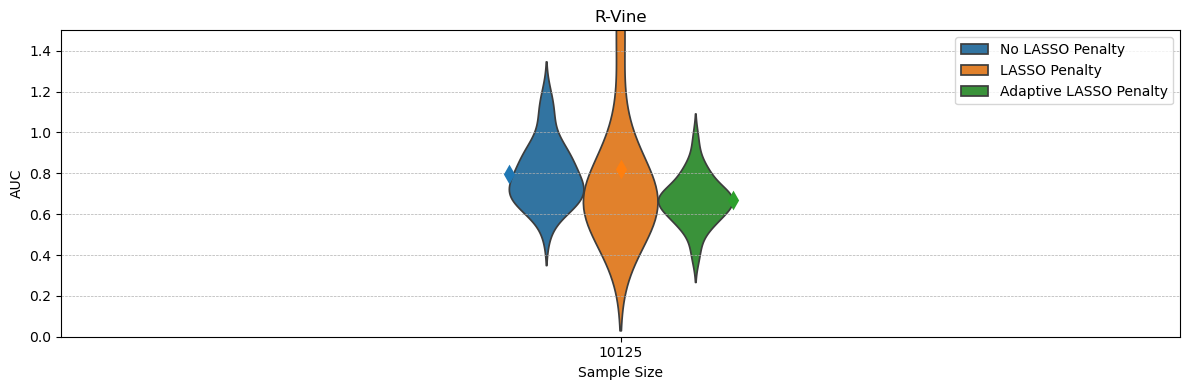

In [43]:
create_comparison_plot_one_scenario(
    kld_dict_no,
    kld_dict_adaptive_2,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.1,
)

create_comparison_violin_plot(
    kld_dict_no,
    kld_dict_adaptive_2,
    kld_dict_adaptive,
    metric = "rel_kld_test",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.0,
    y_max = 1.5,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_normed_hessian, the number is  1


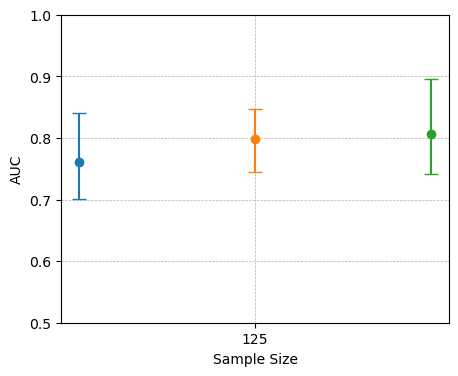

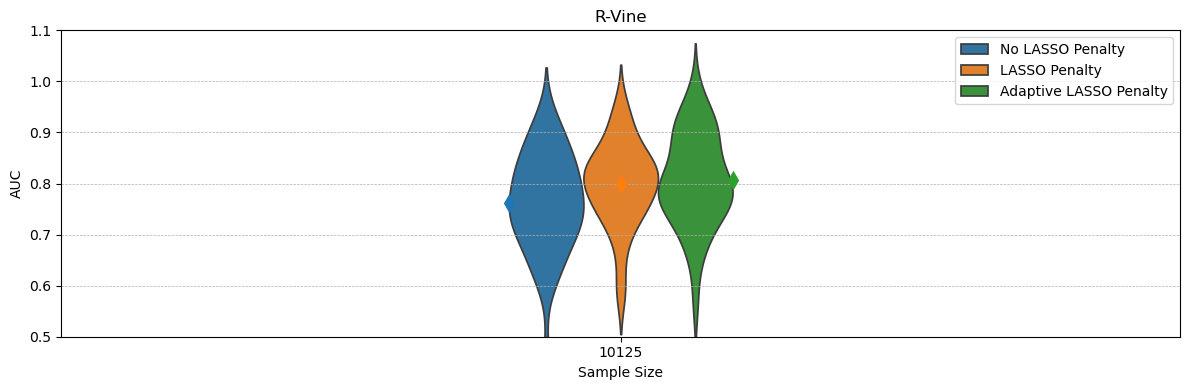

In [44]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_normed_hessian",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_iae, the number is  1


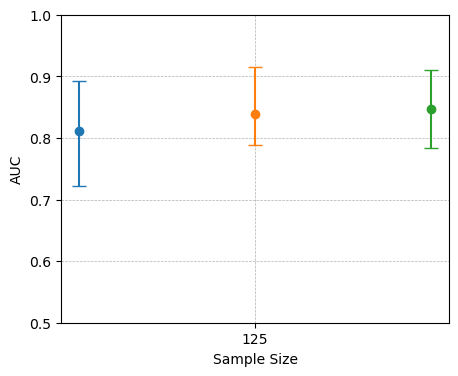

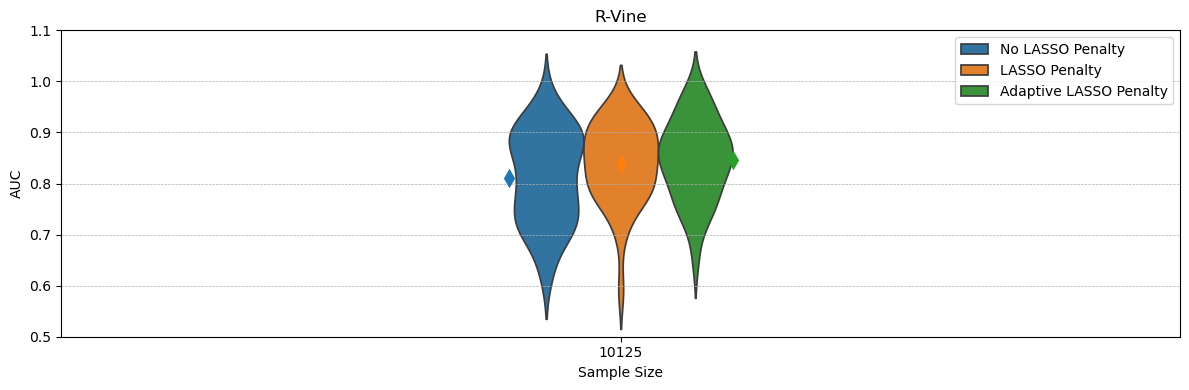

In [45]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_iae",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_iae",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")

there are nan values in metrics.auc_cond_corr, the number is  1


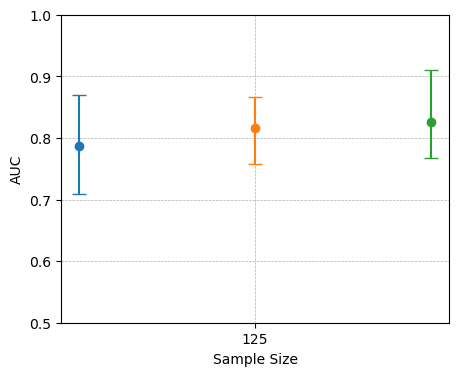

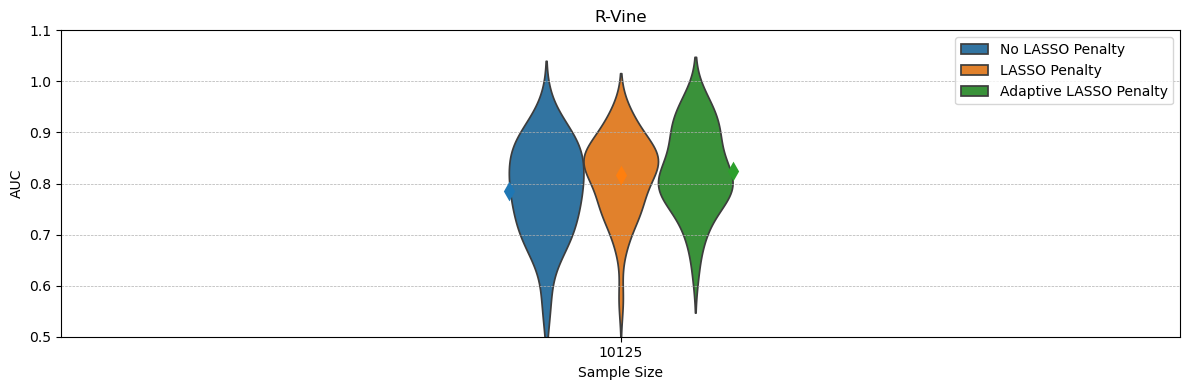

In [46]:
create_comparison_plot_one_scenario(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    title_str = "R-Vine",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1,
)

create_comparison_violin_plot(
    auc_no,
    auc_dict_adaptive_2,
    auc_adaptive,
    metric = "metrics.auc_cond_corr",
    sample_sizes = [125],
    experiment_strings=experiment_name_list,
    y_min = 0.5,
    y_max = 1.1,
    legend=True,
    metric_str="AUC",
)
# save plot
#plt.savefig("gctm_jcgs_plots/rvine_kld_v2.png")